In [2]:
import os
import re
import json
import shutil
import torch
import numpy as np
from datasets import load_dataset, concatenate_datasets
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    set_seed
)
from sklearn.metrics import accuracy_score, f1_score, classification_report
from IPython.display import FileLink
EMOTICON_MODE = "map"

EMOTICON_MAP = {
    ":)))": " rất vui ", ":))": " vui vẻ ", ":)": " vui ",
    "=)))": " cười lớn ", "=))": " cười vui ", ":v": " vui vẻ ",
    "<3": " yêu thích ", ":(((": " rất buồn ", ":((": " buồn ", ":(": " buồn "
}

def clean_text(text):
    text = str(text).strip()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    for emo, meaning in EMOTICON_MAP.items():
        text = text.replace(emo, meaning)
    text = re.sub(r"(?!\d)(.)\1{2,}", r"\1\1", text)
    return re.sub(r"\s+", " ", text).strip()

print("Cell 1: Đã nạp thư viện và hàm tiền xử lý thành công!")

Cell 1: Đã nạp thư viện và hàm tiền xử lý thành công!


1. Đang tải bộ dữ liệu Mạng xã hội (UIT-VSMEC)...


README.md:   0%|          | 0.00/1.17k [00:00<?, ?B/s]

train.json:   0%|          | 0.00/777k [00:00<?, ?B/s]

valid.json:   0%|          | 0.00/96.6k [00:00<?, ?B/s]

test.json:   0%|          | 0.00/96.4k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/5548 [00:00<?, ? examples/s]

... (15 outputs left out)

Map:   0%|          | 0/11426 [00:00<?, ? examples/s]

Map:   0%|          | 0/1583 [00:00<?, ? examples/s]

Map:   0%|          | 0/3166 [00:00<?, ? examples/s]

Cell 2: Tổng số câu Huấn luyện: 16974 | Validation: 2269 | Test: 3859


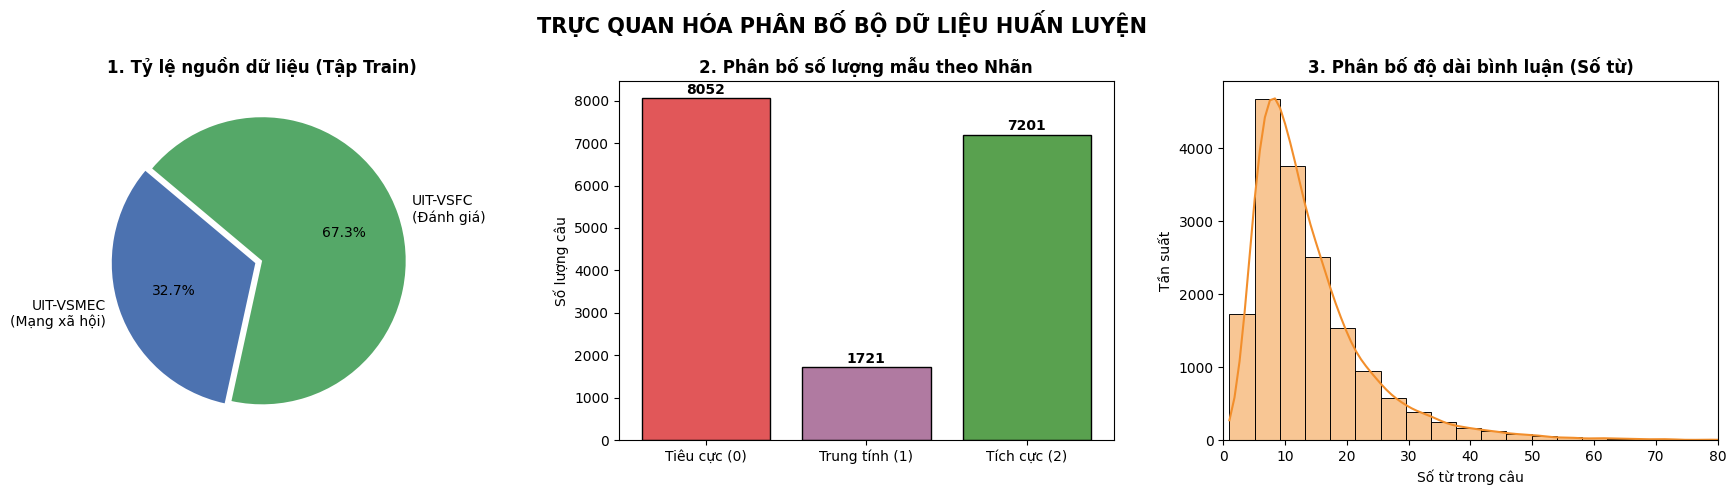

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

print("1. Đang tải bộ dữ liệu Mạng xã hội (UIT-VSMEC)...")
ds_social = load_dataset("tridm/UIT-VSMEC")

def map_social_labels(example):
    emo = example["Emotion"]
    if emo in ["Anger", "Disgust", "Sadness", "Fear"]:
        label = 0  # Tiêu cực
    elif emo in ["Other", "Surprise"]:
        label = 1  # Trung tính
    else:
        label = 2  # Tích cực (Enjoyment)
    return {"text": clean_text(example["Sentence"]), "label": label}

ds_social = ds_social.map(map_social_labels, remove_columns=ds_social["train"].column_names)

print("2. Đang tải bộ dữ liệu Đánh giá mở rộng (UIT-VSFC)...")
ds_review = load_dataset("uitnlp/vietnamese_students_feedback", revision="refs/convert/parquet")

def map_review_labels(example):
    return {"text": clean_text(example["sentence"]), "label": int(example["sentiment"])}

ds_review = ds_review.map(map_review_labels, remove_columns=ds_review["train"].column_names)

# 3. Gộp dữ liệu chuẩn (Mỗi tập chỉ lấy 1 lần, không lặp lại dataset)
train_dataset = concatenate_datasets([ds_social["train"], ds_review["train"]]).shuffle(seed=42)
val_dataset   = concatenate_datasets([ds_social["validation"], ds_review["validation"]])
test_dataset  = concatenate_datasets([ds_social["test"], ds_review["test"]])

print(f"Cell 2: Tổng số câu Huấn luyện: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}")

# 4. Trực quan hóa dữ liệu (Visualize Dataset)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("TRỰC QUAN HÓA PHÂN BỐ BỘ DỮ LIỆU HUẤN LUYỆN", fontsize=15, fontweight="bold")

# Biểu đồ 1: Tỷ lệ nguồn dữ liệu (VSMEC vs VSFC)
domain_counts = [len(ds_social["train"]), len(ds_review["train"])]
axes[0].pie(domain_counts, labels=["UIT-VSMEC\n(Mạng xã hội)", "UIT-VSFC\n(Đánh giá)"], 
            autopct="%1.1f%%", startangle=140, colors=["#4C72B0", "#55A868"], explode=(0.05, 0))
axes[0].set_title("1. Tỷ lệ nguồn dữ liệu (Tập Train)", fontweight="bold")

# Biểu đồ 2: Phân bố 3 nhãn cảm xúc trên Tập Train
label_names = {0: "Tiêu cực (0)", 1: "Trung tính (1)", 2: "Tích cực (2)"}
train_counts = Counter(train_dataset["label"])
labels_x = [label_names[i] for i in [0, 1, 2]]
values_y = [train_counts[i] for i in [0, 1, 2]]
bars = axes[1].bar(labels_x, values_y, color=["#E15759", "#B07AA1", "#59A14F"], edgecolor="black")
axes[1].set_title("2. Phân bố số lượng mẫu theo Nhãn", fontweight="bold")
axes[1].set_ylabel("Số lượng câu")
for bar in bars:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100, 
                 f"{int(bar.get_height())}", ha="center", fontweight="bold")

# Biểu đồ 3: Phân bố độ dài câu (Số từ trên mỗi bình luận)
word_lengths = [len(text.split()) for text in train_dataset["text"]]
sns.histplot(word_lengths, bins=40, kde=True, ax=axes[2], color="#F28E2B")
axes[2].set_xlim(0, 80)
axes[2].set_title("3. Phân bố độ dài bình luận (Số từ)", fontweight="bold")
axes[2].set_xlabel("Số từ trong câu")
axes[2].set_ylabel("Tần suất")

plt.tight_layout()
plt.savefig("dataset_visualization.png", dpi=300)
plt.show()

In [4]:
MODEL_NAME = "uitnlp/visobert"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=128)

print("Đang mã hóa (Tokenize) toàn bộ dữ liệu...")
tokenized_train = train_dataset.map(tokenize_function, batched=True, remove_columns=["text"])
tokenized_val   = val_dataset.map(tokenize_function, batched=True, remove_columns=["text"])
tokenized_test  = test_dataset.map(tokenize_function, batched=True, remove_columns=["text"])

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print("Cell 3: Đã mã hóa dữ liệu hoàn tất!")

config.json:   0%|          | 0.00/644 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B /  471kB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

Đang mã hóa (Tokenize) toàn bộ dữ liệu...


Map:   0%|          | 0/16974 [00:00<?, ? examples/s]

Map:   0%|          | 0/2269 [00:00<?, ? examples/s]

Map:   0%|          | 0/3859 [00:00<?, ? examples/s]

Cell 3: Đã mã hóa dữ liệu hoàn tất!


In [5]:
ID2LABEL = {0: "Tiêu cực", 1: "Trung tính", 2: "Tích cực"}
LABEL2ID = {"Tiêu cực": 0, "Trung tính": 1, "Tích cực": 2}

set_seed(42)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=ID2LABEL,
    label2id=LABEL2ID
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, preds)
    f1_macro = f1_score(labels, preds, average="macro")
    return {"accuracy": acc, "f1_macro": f1_macro}

print("Cell 4: Đã khởi tạo mô hình ViSoBERT(3 nhãn)!")


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  390MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: uitnlp/visobert
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Cell 4: Đã khởi tạo mô hình ViSoBERT(3 nhãn)!


In [6]:
import math
import torch.nn as nn
from sklearn.utils.class_weight import compute_class_weight

BATCH_SIZE = 64
EPOCHS = 5

n_gpu = max(1, torch.cuda.device_count())
steps_per_epoch = math.ceil(len(tokenized_train) / (BATCH_SIZE * n_gpu))
warmup = int(0.1 * steps_per_epoch * EPOCHS)

# 1. Tính trọng số cân bằng tự động cho 3 nhãn (Thay thế cho việc nhân bản dữ liệu)
y_train = np.array(tokenized_train["label"])
class_weights = compute_class_weight(class_weight="balanced", classes=np.array([0, 1, 2]), y=y_train)
# Làm mượt trọng số bằng căn bậc hai để không đẩy lớp Trung tính lên quá cực đoan
smooth_weights = torch.tensor(np.sqrt(class_weights), dtype=torch.float)
print(f"Trọng số hàm Loss cho 3 nhãn [Tiêu cực, Trung tính, Tích cực]: {smooth_weights.tolist()}")

# 2. Định nghĩa Trainer tùy chỉnh tích hợp Class Weights + Label Smoothing
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        loss_fct = nn.CrossEntropyLoss(
            weight=smooth_weights.to(logits.device),
            label_smoothing=0.05
        )
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

training_args = TrainingArguments(
    output_dir="./checkpoints_visobert",
    learning_rate=2e-5,
    per_device_train_batch_size=BATCH_SIZE,   
    per_device_eval_batch_size=128,
    num_train_epochs=EPOCHS,                  
    warmup_steps=warmup,                      
    weight_decay=0.01,
    dataloader_num_workers=2,
    dataloader_pin_memory=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    fp16=torch.cuda.is_available(),
    report_to="none"
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

trainer.train()
print("Cell 5: Huấn luyện hoàn tất!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  390MB            

model.safetensors: downloading bytes:           |  0.00B            

Trọng số hàm Loss cho 3 nhãn [Tiêu cực, Trung tính, Tích cực]: [0.838261604309082, 1.8131804466247559, 0.8864108324050903]


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,0.621285,0.802556,0.736228
2,No log,0.562399,0.835170,0.758826
3,No log,0.576036,0.835610,0.754447
4,0.579064,0.603238,0.858528,0.771795
5,0.579064,0.603991,0.854121,0.775212


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Cell 5: Huấn luyện hoàn tất!


In [7]:
print("KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST:")
test_output = trainer.predict(tokenized_test)
test_preds = np.argmax(test_output.predictions, axis=-1)
print(classification_report(tokenized_test["label"], test_preds, target_names=["Tiêu cực", "Trung tính", "Tích cực"], digits=4))

SAVE_DIR = "./Model_viso_bert_v2"
os.makedirs(SAVE_DIR, exist_ok=True)

trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

inference_cfg = {
    "temperature": 1.3,
    "emoji_mode": "keep",
    "max_len": 128,
    "labels": ["neg", "neu", "pos"]
}
with open(os.path.join(SAVE_DIR, "inference_config.json"), "w", encoding="utf-8") as f:
    json.dump(inference_cfg, f, ensure_ascii=False, indent=2)

shutil.make_archive("Model_viso_bert_v2", "zip", SAVE_DIR)
print("\nĐÃ ĐÓNG GÓI XONG 5 FILE! Hãy bấm vào dòng link màu xanh bên dưới để tải về máy:")
FileLink(r"Model_viso_bert_v2.zip")

KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST:


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

    Tiêu cực     0.8869    0.9088    0.8977      1743
  Trung tính     0.5298    0.5075    0.5184       333
    Tích cực     0.9128    0.8979    0.9053      1783

    accuracy                         0.8691      3859
   macro avg     0.7765    0.7714    0.7738      3859
weighted avg     0.8680    0.8691    0.8685      3859



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


ĐÃ ĐÓNG GÓI XONG 5 FILE! Hãy bấm vào dòng link màu xanh bên dưới để tải về máy:


/kaggle/working/Model_viso_bert_v2.zip

Map:   0%|          | 0/693 [00:00<?, ? examples/s]

Map:   0%|          | 0/3166 [00:00<?, ? examples/s]

⏳ Đang train bản KHÔNG trọng số (cùng seed, cùng siêu tham số với bản Đề xuất)...


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: uitnlp/visobert
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return 

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,0.534449,0.817541,0.695689
2,No log,0.481581,0.847951,0.745669
3,No log,0.491705,0.861172,0.774006
4,0.495025,0.503443,0.864698,0.764780
5,0.495025,0.508763,0.861613,0.769132


... (15 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]



SO SÁNH TRÊN TẬP TEST GỘP (cùng seed, chỉ khác trọng số lớp):


,Cấu hình,Macro-F1 gộp,Recall Tiêu cực gộp,Recall Trung tính gộp,Macro-F1 VSMEC,Macro-F1 VSFC,Tiêu cực→Trung tính,Tiêu cực→Tích cực,Bỏ lọt tổng
0,Không trọng số (chạy thật),0.7618,0.9094,0.4024,0.6913,0.7358,58,100,158
1,Mô phỏng (trừ ln trọng số),0.7603,0.9260,0.4024,NaN,NaN,,,
2,Có trọng số (Đề xuất),0.7738,0.9088,0.5075,0.6884,0.7644,92,67,159



GHI CHÚ: dòng 'Mô phỏng' là cách cũ (trừ ln trọng số khỏi logit Trung tính). Chỉ dòng 'chạy thật' mới được gọi là 'Không trọng số' trong báo cáo.
Một seed duy nhất: chênh Macro-F1 dưới ~0.01 coi như nằm trong nhiễu, không kết luận hơn/thua.
✅ Đã lưu ảnh bảng: bang_5_1_that.png


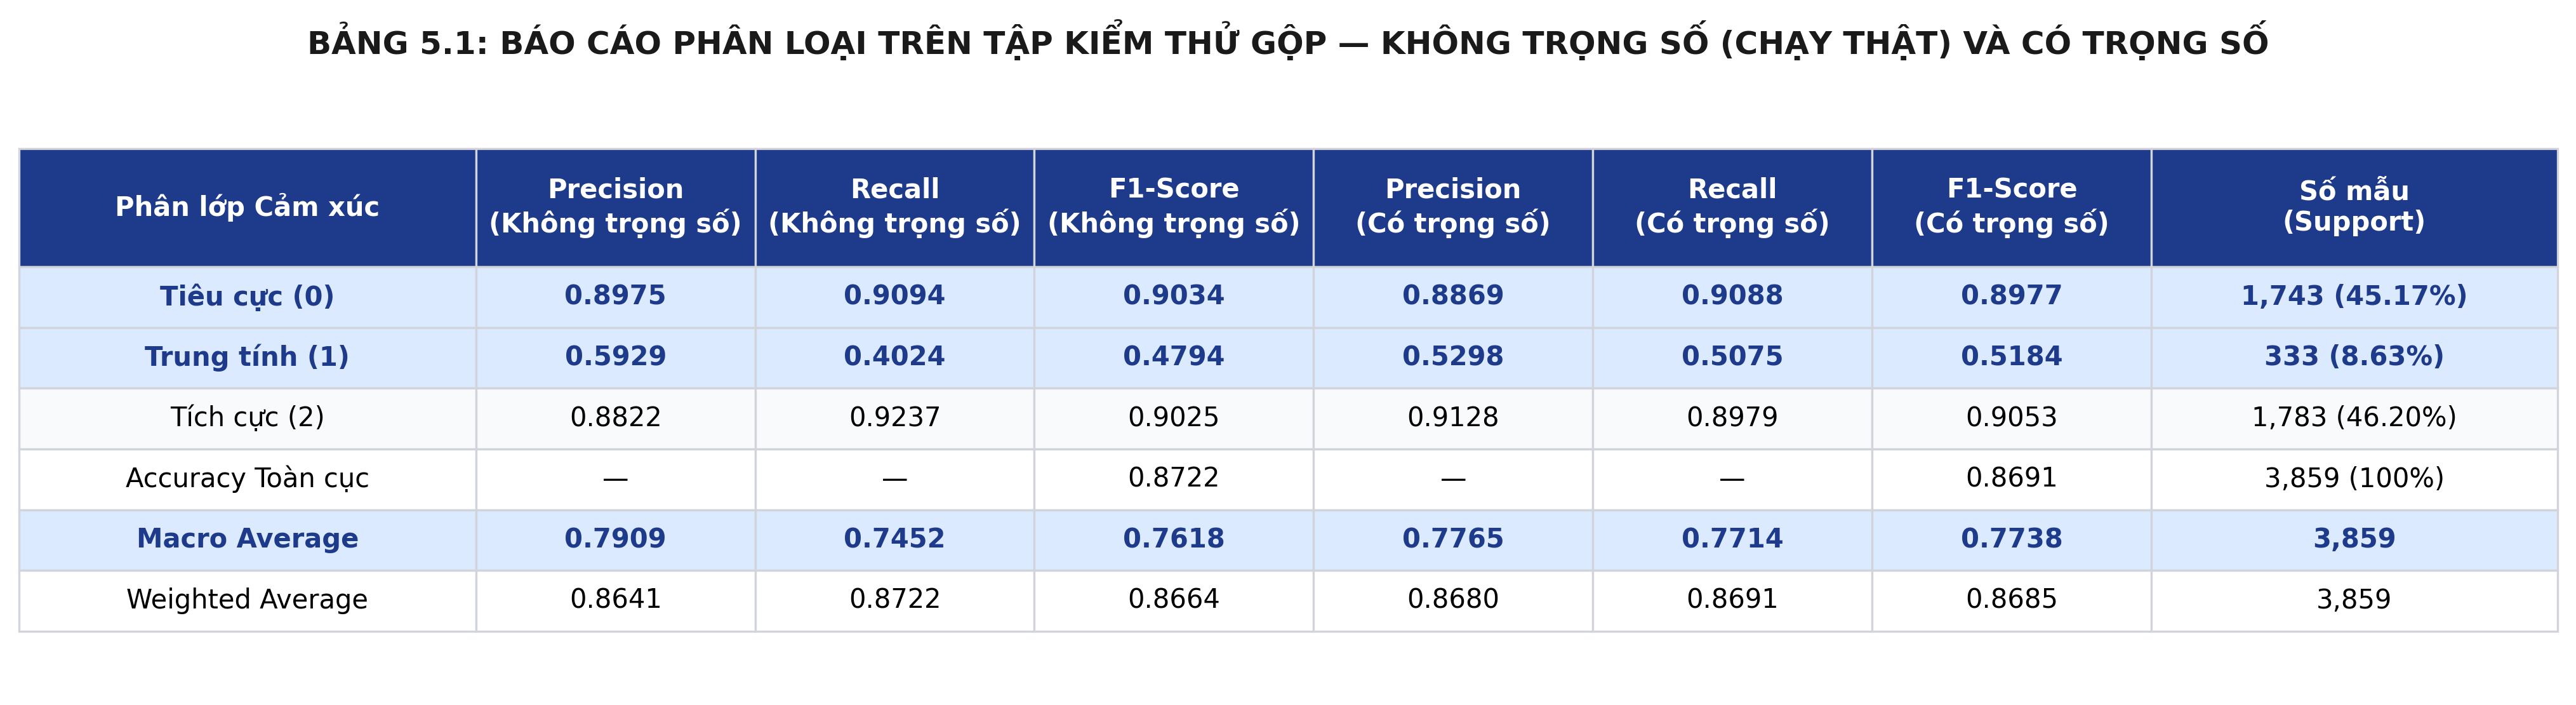

✅ Đã lưu ảnh bảng: bang_5_2_that.png


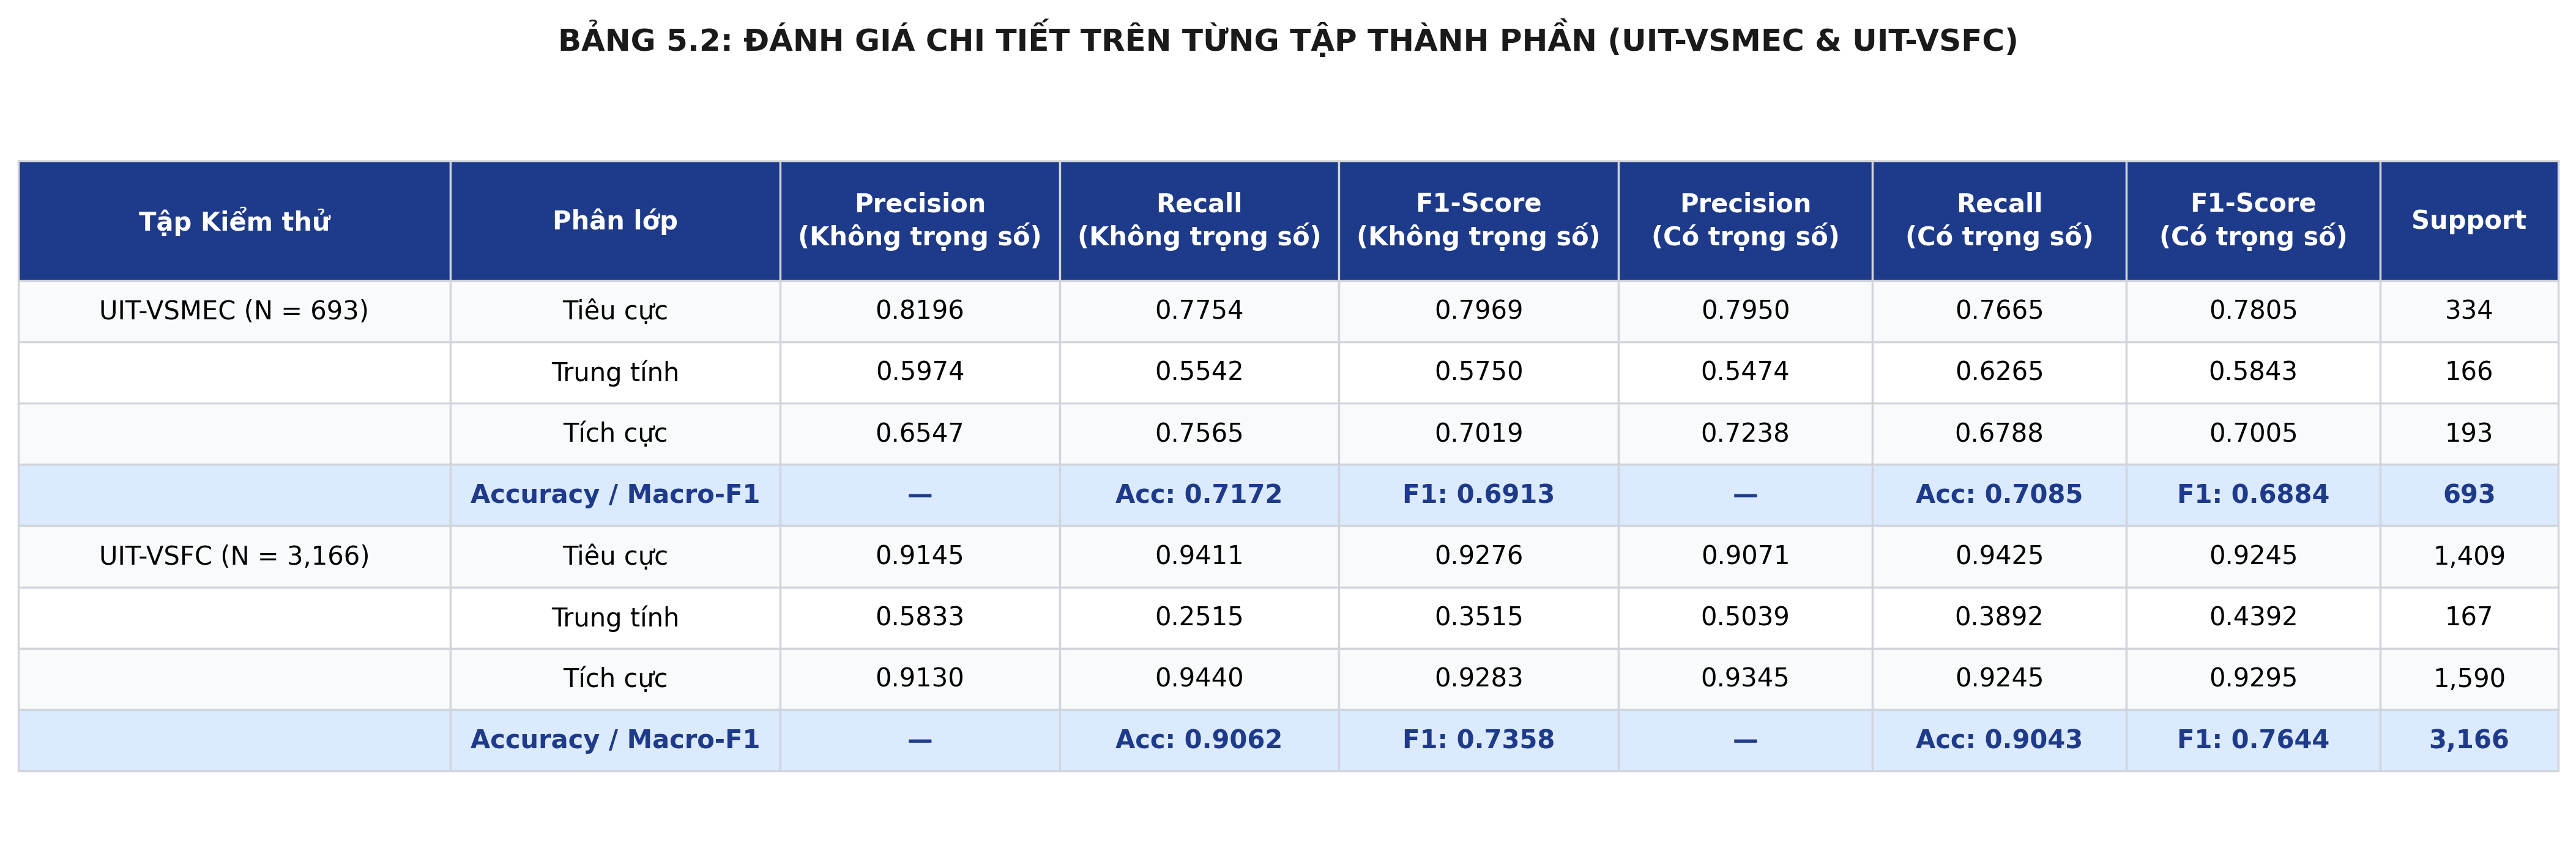

✅ Đã lưu ảnh bảng: bang_5_3_that.png


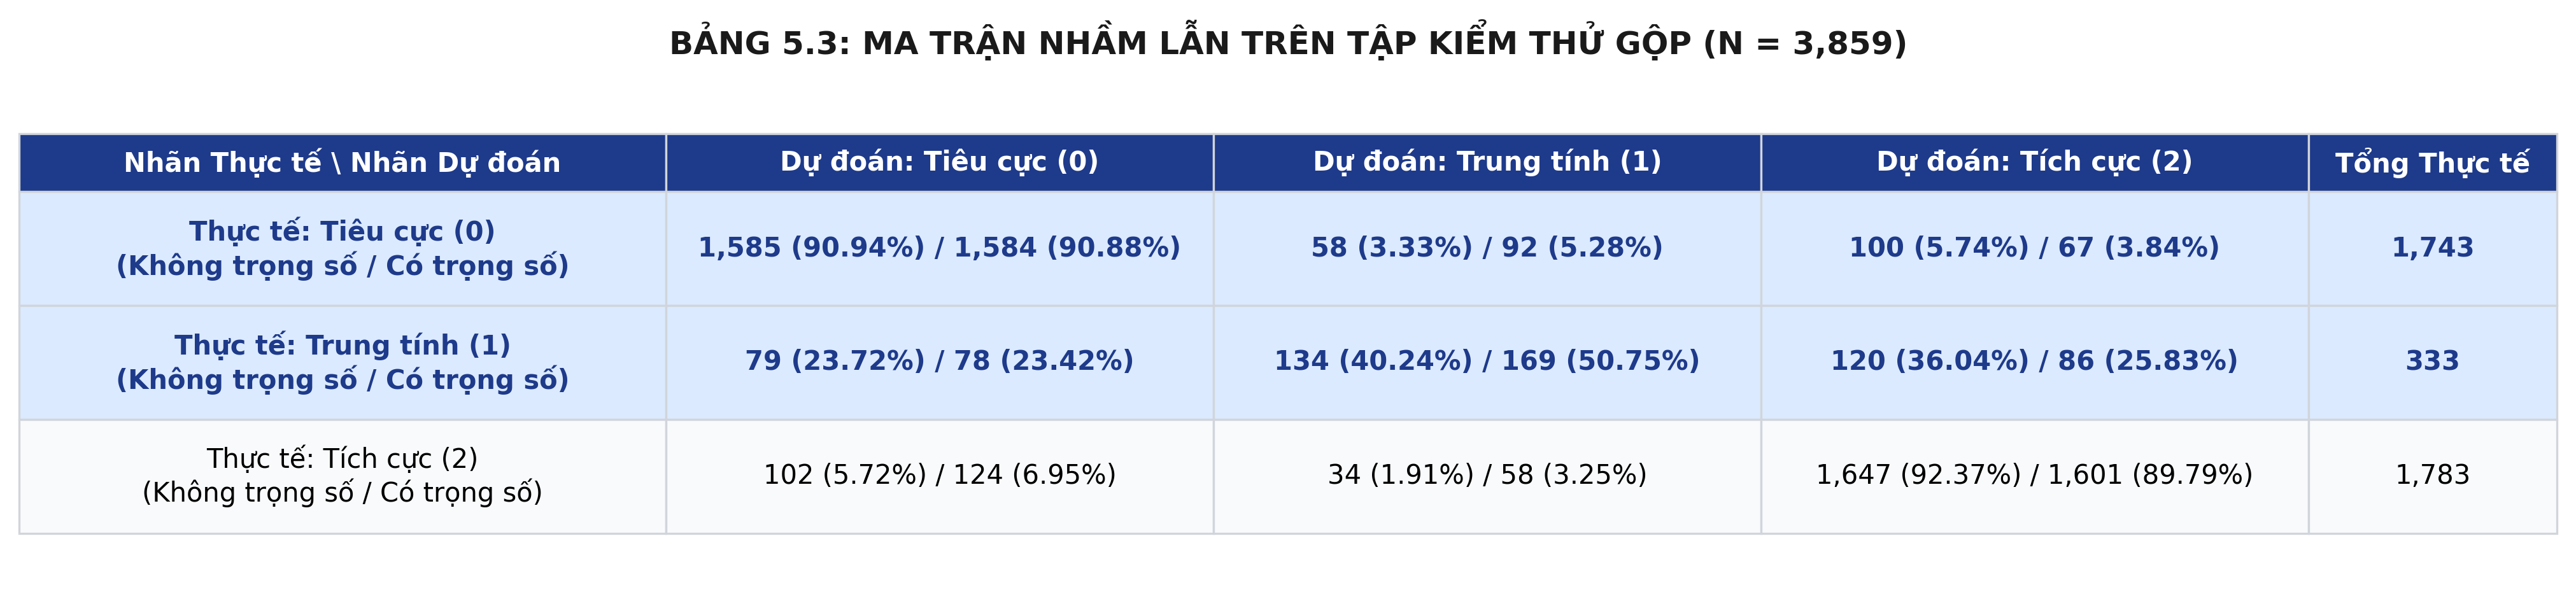

Đã lưu: so_sanh_trong_so.json, so_sanh_trong_so.csv, bang_5_1_that.png, bang_5_2_that.png, bang_5_3_that.png


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


1) HIỆU CHUẨN XÁC SUẤT (ECE càng thấp càng chuẩn; accuracy không đổi khi chia T):


,Nhiệt độ,NLL val,ECE val,NLL test,ECE test
0,T = 1.0 (không chia),0.4144,0.0390,0.3905,0.0343
1,T = 1.3 (đang dùng trong app),0.4137,0.0499,0.3924,0.0515
2,T = 1.15 (tối ưu NLL trên validation),0.4089,0.0443,0.3864,0.0350


   -> T tối ưu trên validation = 1.15
   -> T* > 1: model quá tự tin; chia T giúp ích. Dùng T* = 1.15 thay cho 1.3 nếu ECE test giảm.

2) DÒ b TRÊN MODEL CÓ TRỌNG SỐ (b chọn trên validation; mong đợi b gần 0 vì trọng số đã bù Trung tính):


... (4 outputs left out)

,Ngưỡng τ,Phủ (% câu giữ lại),Accuracy phần giữ lại (%),Số câu bị đẩy sang kiểm tra tay
0,0.50,97.1,88.15,113
1,0.60,92.4,90.19,292
2,0.70,88.7,91.50,437
3,0.80,82.0,93.71,694
4,0.90,68.5,96.37,1217
5,0.95,6.1,94.89,3624



4) LUẬT 'HỖN HỢP' (min(P_neg, P_pos) >= 0.25) KÍCH HOẠT BAO NHIÊU LẦN TRÊN TEST:


,Nhiệt độ,Số câu kích hoạt 'Hỗn hợp',Tỷ lệ (% test),Nhãn thật = Tiêu cực,Nhãn thật = Trung tính,Nhãn thật = Tích cực
0,T = 1.0,115,2.98,38,15,62
1,T = 1.3,136,3.52,46,23,67
2,T = 1.15,126,3.27,42,20,64


   (Tập test không có nhãn 'Hỗn hợp' nên chỉ đếm được tần suất và nhãn thật của các câu bị kích hoạt, chưa đo được độ đúng của nhãn này.)
   - [Tiêu cực] nhà thì không xa lắm nhưng chưa bao giờ đi vì sợ bị đè bẹp luôn người cười lớn )) | Neg 0.32 Neu 0.07 Pos 0.60
   - [Tích cực] mệt vãi .. mà cừời cũng vãi ?? | Neg 0.45 Neu 0.06 Pos 0.49
   - [Tiêu cực] nhìn thôi cũng đau lòng vui vẻ | Neg 0.61 Neu 0.10 Pos 0.29
   - [Trung tính] hình như bồ tao cũng tập gym 😶😶 | Neg 0.39 Neu 0.22 Pos 0.39
   - [Tiêu cực] 😞 đó sẽ là những kỉ niệm thật đẹp | Neg 0.48 Neu 0.24 Pos 0.28
   - [Tích cực] hồi xưa làm fanpage được gạ kèo 7 triệu nhưng nhất quyết không bán . cảm thấy quyết định đ | Neg 0.27 Neu 0.10 Pos 0.63
   - [Tiêu cực] mức thu cao nhất - đồng ý vì số liệu nó thể hiện như vậy , chứ còn hiệu quả thì mình không | Neg 0.27 Neu 0.38 Pos 0.36
   - [Tích cực] con gái tao thì suốt ngày hêy siri bắt chước mẹ 😂 | Neg 0.56 Neu 0.18 Pos 0.26

Đã lưu: hieu_chuan_model_cuoi.json


In [8]:
# =====================================================================
# HAI CELL MỚI — dán vào notebook SAU các cell hiện có (cần còn `trainer`, `tokenized_val`,
# `tokenized_test`, `smooth_weights`, `ds_social`, `ds_review`, `test_dataset` trong bộ nhớ).
#
#   CELL A : train thật bản KHÔNG trọng số (chỉ khác bản Đề xuất ở đúng 1 chỗ: trọng số lớp)
#            rồi dựng lại Bảng 5.1 / 5.2 / 5.3 "trước - sau" bằng số ĐO THẬT (khoảng 13 phút).
#   CELL B : không train. Đo hiệu chuẩn xác suất (T, ECE), dò b trên model có trọng số,
#            bảng ngưỡng tự tin, và tần suất luật "Hỗn hợp" kích hoạt (vài chục giây).
#
# Hai cell KHÔNG đổi biến `trainer` và KHÔNG ghi đè model đã lưu.
# =====================================================================


# %% CELL A — Bản không trọng số thật + bảng trước/sau đo thật
import gc, json, math, time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

TEN_GOC = "Không trọng số"
TEN_DX = "Có trọng số"
SEED = 42


def export_table_image2(title, headers, data, filename, col_widths=None, figsize=(11, 4), highlight_rows=None):
    """Giống export_table_image cũ nhưng tiêu đề nhiều dòng không bị cắt chữ."""
    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    ax.axis("off")
    plt.title(title, fontsize=12, fontweight="bold", pad=15, loc="center", color="#1a1a1a")
    table = ax.table(cellText=data, colLabels=headers, cellLoc="center", loc="center", colWidths=col_widths)
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.8)
    h0 = table[(1, 0)].get_height()                      # chiều cao mặc định của 1 dòng chữ
    so_dong = [max(str(c).count("\n") + 1 for c in hang) for hang in [headers] + [list(r) for r in data]]
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("#d1d5db")
        cell.set_linewidth(0.8)
        cell.set_height(h0 * (1 + 0.95 * (so_dong[row] - 1)))   # ô nhiều dòng thì cao tương ứng, không bị cắt chữ
        if row == 0:
            cell.set_text_props(weight="bold", color="#ffffff")
            cell.set_facecolor("#1e3a8a")
        else:
            if highlight_rows and (row - 1) in highlight_rows:
                cell.set_facecolor("#dbeafe")
                cell.set_text_props(weight="bold", color="#1e3a8a")
            else:
                cell.set_facecolor("#f8fafc" if row % 2 == 1 else "#ffffff")
    plt.tight_layout()
    plt.savefig(filename, bbox_inches="tight", dpi=300)
    plt.close()
    print(f"✅ Đã lưu ảnh bảng: {filename}")
    try:
        display(Image(filename=filename))
    except Exception:
        pass


def mo_phong_khong_trong_so(logits, smooth_w):
    """Cách cũ: trừ ln(w_TrungTinh / w_TieuCuc) khỏi logit Trung tính của model có trọng số (chỉ là xấp xỉ)."""
    z = np.array(logits, dtype=np.float64, copy=True)
    z[:, 1] -= float(np.log(float(smooth_w[1]) / float(smooth_w[0])))
    return z.argmax(-1)


def dung_bang(L_goc, L_dx, LABELS, smooth_w=None):
    """Từ logit của hai model, tính mọi thứ cần cho Bảng 5.1/5.2/5.3 và bảng tóm tắt."""
    rep = {}
    for ten, L in (("goc", L_goc), ("dx", L_dx)):
        rep[ten] = {k: classification_report(LABELS[k], L[k].argmax(-1), output_dict=True, digits=4, zero_division=0)
                    for k in LABELS}
    cm = {ten: confusion_matrix(LABELS["GOP"], L["GOP"].argmax(-1)) for ten, L in (("goc", L_goc), ("dx", L_dx))}
    tom_tat = {}
    for ten, L in (("goc", L_goc), ("dx", L_dx)):
        c = cm[ten]
        tom_tat[ten] = {
            "macro_f1_gop": rep[ten]["GOP"]["macro avg"]["f1-score"],
            "macro_f1_vsmec": rep[ten]["VSMEC"]["macro avg"]["f1-score"],
            "macro_f1_vsfc": rep[ten]["VSFC"]["macro avg"]["f1-score"],
            "acc_gop": rep[ten]["GOP"]["accuracy"],
            "recall_neg_gop": rep[ten]["GOP"]["0"]["recall"],
            "recall_neu_gop": rep[ten]["GOP"]["1"]["recall"],
            "neg_thanh_neu": int(c[0, 1]), "neg_thanh_pos": int(c[0, 2]),
            "bo_lot_tong": int(c[0, 1] + c[0, 2]), "so_neg": int(c[0].sum()),
        }
    if smooth_w is not None:
        pm = mo_phong_khong_trong_so(L_dx["GOP"], smooth_w)
        tom_tat["mo_phong"] = {
            "macro_f1_gop": f1_score(LABELS["GOP"], pm, average="macro"),
            "recall_neg_gop": float((pm[LABELS["GOP"] == 0] == 0).mean()),
            "recall_neu_gop": float((pm[LABELS["GOP"] == 1] == 1).mean()),
        }
    return rep, cm, tom_tat


def in_tom_tat(tom_tat):
    import pandas as pd
    rows = []
    for ten, nhan in (("goc", f"{TEN_GOC} (chạy thật)"), ("mo_phong", "Mô phỏng (trừ ln trọng số)"), ("dx", f"{TEN_DX} (Đề xuất)")):
        if ten not in tom_tat:
            continue
        t = tom_tat[ten]
        rows.append({
            "Cấu hình": nhan,
            "Macro-F1 gộp": round(t["macro_f1_gop"], 4),
            "Recall Tiêu cực gộp": round(t["recall_neg_gop"], 4),
            "Recall Trung tính gộp": round(t["recall_neu_gop"], 4),
            "Macro-F1 VSMEC": round(t.get("macro_f1_vsmec", float("nan")), 4),
            "Macro-F1 VSFC": round(t.get("macro_f1_vsfc", float("nan")), 4),
            "Tiêu cực→Trung tính": t.get("neg_thanh_neu", ""),
            "Tiêu cực→Tích cực": t.get("neg_thanh_pos", ""),
            "Bỏ lọt tổng": t.get("bo_lot_tong", ""),
        })
    df = pd.DataFrame(rows)
    display(df)
    return df


def xuat_3_bang(rep, cm, LABELS):
    n_total = len(LABELS["GOP"])
    f = lambda x: f"{x:.4f}"
    h51 = ["Phân lớp Cảm xúc",
           f"Precision\n({TEN_GOC})", f"Recall\n({TEN_GOC})", f"F1-Score\n({TEN_GOC})",
           f"Precision\n({TEN_DX})", f"Recall\n({TEN_DX})", f"F1-Score\n({TEN_DX})", "Số mẫu\n(Support)"]
    g, d = rep["goc"]["GOP"], rep["dx"]["GOP"]
    d51 = []
    for k, ten in (("0", "Tiêu cực (0)"), ("1", "Trung tính (1)"), ("2", "Tích cực (2)")):
        d51.append([ten, f(g[k]["precision"]), f(g[k]["recall"]), f(g[k]["f1-score"]),
                    f(d[k]["precision"]), f(d[k]["recall"]), f(d[k]["f1-score"]),
                    f"{int(d[k]['support']):,} ({d[k]['support'] / n_total * 100:.2f}%)"])
    d51.append(["Accuracy Toàn cục", "—", "—", f(g["accuracy"]), "—", "—", f(d["accuracy"]), f"{n_total:,} (100%)"])
    for k, ten in (("macro avg", "Macro Average"), ("weighted avg", "Weighted Average")):
        d51.append([ten, f(g[k]["precision"]), f(g[k]["recall"]), f(g[k]["f1-score"]),
                    f(d[k]["precision"]), f(d[k]["recall"]), f(d[k]["f1-score"]), f"{n_total:,}"])
    export_table_image2("BẢNG 5.1: BÁO CÁO PHÂN LOẠI TRÊN TẬP KIỂM THỬ GỘP — KHÔNG TRỌNG SỐ (CHẠY THẬT) VÀ CÓ TRỌNG SỐ",
                        h51, d51, "bang_5_1_that.png",
                        col_widths=[0.18, 0.11, 0.11, 0.11, 0.11, 0.11, 0.11, 0.16], figsize=(13.5, 3.8),
                        highlight_rows=[0, 1, 4])

    h52 = ["Tập Kiểm thử", "Phân lớp",
           f"Precision\n({TEN_GOC})", f"Recall\n({TEN_GOC})", f"F1-Score\n({TEN_GOC})",
           f"Precision\n({TEN_DX})", f"Recall\n({TEN_DX})", f"F1-Score\n({TEN_DX})", "Support"]
    d52 = []
    for key, ten_tap in (("VSMEC", "UIT-VSMEC (N = 693)"), ("VSFC", "UIT-VSFC (N = 3,166)")):
        g, d = rep["goc"][key], rep["dx"][key]
        for i, (k, ten) in enumerate((("0", "Tiêu cực"), ("1", "Trung tính"), ("2", "Tích cực"))):
            d52.append([ten_tap if i == 0 else "", ten,
                        f(g[k]["precision"]), f(g[k]["recall"]), f(g[k]["f1-score"]),
                        f(d[k]["precision"]), f(d[k]["recall"]), f(d[k]["f1-score"]), f"{int(d[k]['support']):,}"])
        d52.append(["", "Accuracy / Macro-F1", "—", f"Acc: {g['accuracy']:.4f}", f"F1: {g['macro avg']['f1-score']:.4f}",
                    "—", f"Acc: {d['accuracy']:.4f}", f"F1: {d['macro avg']['f1-score']:.4f}", f"{int(d['macro avg']['support']):,}"])
    export_table_image2("BẢNG 5.2: ĐÁNH GIÁ CHI TIẾT TRÊN TỪNG TẬP THÀNH PHẦN (UIT-VSMEC & UIT-VSFC)",
                        h52, d52, "bang_5_2_that.png",
                        col_widths=[0.17, 0.13, 0.11, 0.11, 0.11, 0.10, 0.10, 0.10, 0.07], figsize=(14, 4.8),
                        highlight_rows=[3, 7])

    h53 = ["Nhãn Thực tế \\ Nhãn Dự đoán", "Dự đoán: Tiêu cực (0)", "Dự đoán: Trung tính (1)",
           "Dự đoán: Tích cực (2)", "Tổng Thực tế"]
    d53 = []
    for i, ten in enumerate(["Thực tế: Tiêu cực (0)", "Thực tế: Trung tính (1)", "Thực tế: Tích cực (2)"]):
        s = cm["dx"][i].sum()
        cells = [f"{cm['goc'][i, j]:,} ({cm['goc'][i, j] / s * 100:.2f}%) / {cm['dx'][i, j]:,} ({cm['dx'][i, j] / s * 100:.2f}%)"
                 for j in range(3)]
        d53.append([f"{ten}\n({TEN_GOC} / {TEN_DX})"] + cells + [f"{s:,}"])
    export_table_image2("BẢNG 5.3: MA TRẬN NHẦM LẪN TRÊN TẬP KIỂM THỬ GỘP (N = 3,859)",
                        h53, d53, "bang_5_3_that.png",
                        col_widths=[0.26, 0.22, 0.22, 0.22, 0.10], figsize=(13.5, 3.2), highlight_rows=[0, 1])


# ---------------- Huấn luyện bản không trọng số (chỉ chạy khi có trainer thật) ----------------
from transformers import (AutoModelForSequenceClassification, Trainer, TrainingArguments,
                          EarlyStoppingCallback, set_seed)

CHAY_LAI = True          # đặt False nếu đã chạy cell này rồi và còn `L_goc` trong bộ nhớ

for ten_bien, ds in (("tok_test_vsmec", ds_social["test"]), ("tok_test_vsfc", ds_review["test"])):
    if ten_bien not in globals():
        globals()[ten_bien] = ds.map(tokenize_function, batched=True, remove_columns=["text"])

LABELS = {"GOP": np.array(list(tokenized_test["label"])),
          "VSMEC": np.array(list(tok_test_vsmec["label"])),
          "VSFC": np.array(list(tok_test_vsfc["label"]))}


def lay_logits(tr):
    return {"GOP": tr.predict(tokenized_test).predictions,
            "VSMEC": tr.predict(tok_test_vsmec).predictions,
            "VSFC": tr.predict(tok_test_vsfc).predictions}


class PlainTrainer(Trainer):
    """Y hệt WeightedTrainer, chỉ BỎ trọng số lớp (vẫn giữ label smoothing 0.05)."""
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        loss_fct = nn.CrossEntropyLoss(label_smoothing=0.05)
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


if CHAY_LAI or "L_goc" not in globals():
    t0 = time.time()
    print("⏳ Đang train bản KHÔNG trọng số (cùng seed, cùng siêu tham số với bản Đề xuất)...")
    gc.collect()
    torch.cuda.empty_cache()                    # nhường bộ nhớ GPU cho lần train thứ hai
    set_seed(SEED)
    m_goc =AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID)
    args_goc = TrainingArguments(
        output_dir="./ckpt_khong_trong_so", learning_rate=2e-5,
        per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=128,
        num_train_epochs=EPOCHS, warmup_steps=warmup, weight_decay=0.01,
        dataloader_num_workers=2, dataloader_pin_memory=True,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="f1_macro",
        fp16=torch.cuda.is_available(), report_to="none")
    trainer_goc = PlainTrainer(
        model=m_goc, args=args_goc, train_dataset=tokenized_train, eval_dataset=tokenized_val,
        data_collator=data_collator, compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
    trainer_goc.train()
    L_goc = lay_logits(trainer_goc)
    np.savez("logits_khong_trong_so.npz", **L_goc)          # lưu lại phòng khi kernel chết
    print(f"Xong bản không trọng số sau {(time.time() - t0) / 60:.1f} phút")
    del m_goc, trainer_goc
    gc.collect()
    torch.cuda.empty_cache()

L_dx = lay_logits(trainer)
rep, cm, tom_tat = dung_bang(L_goc, L_dx, LABELS, smooth_weights)
print("\nSO SÁNH TRÊN TẬP TEST GỘP (cùng seed, chỉ khác trọng số lớp):")
df_tom_tat = in_tom_tat(tom_tat)
print("\nGHI CHÚ: dòng 'Mô phỏng' là cách cũ (trừ ln trọng số khỏi logit Trung tính). "
      "Chỉ dòng 'chạy thật' mới được gọi là 'Không trọng số' trong báo cáo.")
print("Một seed duy nhất: chênh Macro-F1 dưới ~0.01 coi như nằm trong nhiễu, không kết luận hơn/thua.")
xuat_3_bang(rep, cm, LABELS)
with open("so_sanh_trong_so.json", "w", encoding="utf-8") as f:
    json.dump(tom_tat, f, ensure_ascii=False, indent=2)
df_tom_tat.to_csv("so_sanh_trong_so.csv", index=False, encoding="utf-8-sig")
print("Đã lưu: so_sanh_trong_so.json, so_sanh_trong_so.csv, bang_5_1_that.png, bang_5_2_that.png, bang_5_3_that.png")


# %% CELL B — Hiệu chuẩn (T, ECE), dò b trên model có trọng số, ngưỡng tự tin, luật "Hỗn hợp"
import json
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from IPython.display import display

N_BIN = 15


def softmax(z, T=1.0):
    z = np.asarray(z, dtype=np.float64) / T
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def nll(z, y, T=1.0):
    p = softmax(z, T)
    return float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-12, None)).mean())


def ece(z, y, T=1.0, n_bin=N_BIN):
    p = softmax(z, T)
    conf, pred = p.max(1), p.argmax(1)
    ok = (pred == y).astype(float)
    edges = np.linspace(0.0, 1.0, n_bin + 1)
    tot = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            tot += m.mean() * abs(ok[m].mean() - conf[m].mean())
    return float(tot)


def fit_T(z, y, grid=None):
    grid = np.arange(0.5, 3.0001, 0.05) if grid is None else grid
    losses = [nll(z, y, T) for T in grid]
    return float(grid[int(np.argmin(losses))])


def bang_hieu_chuan(zv, yv, zt, yt, T_dung=1.3):
    T_opt = fit_T(zv, yv)
    rows = []
    for ten, T in (("T = 1.0 (không chia)", 1.0), (f"T = {T_dung} (đang dùng trong app)", T_dung),
                   (f"T = {T_opt:.2f} (tối ưu NLL trên validation)", T_opt)):
        rows.append({"Nhiệt độ": ten, "NLL val": round(nll(zv, yv, T), 4), "ECE val": round(ece(zv, yv, T), 4),
                     "NLL test": round(nll(zt, yt, T), 4), "ECE test": round(ece(zt, yt, T), 4)})
    return T_opt, pd.DataFrame(rows)


def bang_nguong(zt, yt, T, taus=(0.5, 0.6, 0.7, 0.8, 0.9, 0.95)):
    p = softmax(zt, T)
    conf, pred = p.max(1), p.argmax(1)
    rows = []
    for tau in taus:
        m = conf >= tau
        rows.append({"Ngưỡng τ": tau, "Phủ (% câu giữ lại)": round(m.mean() * 100, 1),
                     "Accuracy phần giữ lại (%)": round((pred[m] == yt[m]).mean() * 100, 2) if m.any() else float("nan"),
                     "Số câu bị đẩy sang kiểm tra tay": int((~m).sum())})
    return pd.DataFrame(rows)


def bang_do_b(zv, yv, zt, yt, grid=None):
    grid = np.arange(-1.5, 1.5001, 0.25) if grid is None else grid
    rows = []
    for b in grid:
        a, c = zv.copy(), zt.copy()
        a[:, 1] += b
        c[:, 1] += b
        pc = c.argmax(1)
        rows.append({"b": round(float(b), 2),
                     "val macro-F1": round(f1_score(yv, a.argmax(1), average="macro"), 4),
                     "test macro-F1": round(f1_score(yt, pc, average="macro"), 4),
                     "test recall Tiêu cực": round(float((pc[yt == 0] == 0).mean()), 4),
                     "test recall Trung tính": round(float((pc[yt == 1] == 1).mean()), 4)})
    df = pd.DataFrame(rows)
    b_best = float(df.loc[df["val macro-F1"].idxmax(), "b"])      # chọn theo VALIDATION
    return b_best, df


def bang_hon_hop(zt, yt, Ts, nguong=0.25):
    rows = []
    for ten, T in Ts:
        p = softmax(zt, T)
        m = np.minimum(p[:, 0], p[:, 2]) >= nguong
        row = {"Nhiệt độ": ten, "Số câu kích hoạt 'Hỗn hợp'": int(m.sum()), "Tỷ lệ (% test)": round(m.mean() * 100, 2)}
        for k, ten_lop in ((0, "Tiêu cực"), (1, "Trung tính"), (2, "Tích cực")):
            row[f"Nhãn thật = {ten_lop}"] = int((m & (yt == k)).sum())
        rows.append(row)
    return pd.DataFrame(rows)


val_out = trainer.predict(tokenized_val)
zv, yv = val_out.predictions, np.array(val_out.label_ids)
te_out = trainer.predict(tokenized_test)
zt, yt = te_out.predictions, np.array(list(tokenized_test["label"]))
T_APP = 1.3

print("1) HIỆU CHUẨN XÁC SUẤT (ECE càng thấp càng chuẩn; accuracy không đổi khi chia T):")
T_opt, df_hc = bang_hieu_chuan(zv, yv, zt, yt, T_APP)
display(df_hc)
print(f"   -> T tối ưu trên validation = {T_opt:.2f}")
if T_opt <= 0.5 or T_opt >= 3.0:
    print("   ⚠ T* nằm sát mép lưới dò (0.5–3.0): kết quả không đáng tin, cần xem lại logit.")
elif abs(T_opt - 1.0) <= 0.1:
    print(f"   -> T* ≈ 1: model đã khá chuẩn, không có căn cứ để chia thêm {T_APP}.")
elif T_opt > 1.0:
    print(f"   -> T* > 1: model quá tự tin; chia T giúp ích. Dùng T* = {T_opt:.2f} thay cho {T_APP} nếu ECE test giảm.")
else:
    print(f"   -> T* < 1: model đang THIẾU tự tin; chia {T_APP} làm xác suất tệ hơn (xem ECE ở bảng trên).")

print("\n2) DÒ b TRÊN MODEL CÓ TRỌNG SỐ (b chọn trên validation; mong đợi b gần 0 vì trọng số đã bù Trung tính):")
b_best, df_b = bang_do_b(zv, yv, zt, yt)
display(df_b)
print(f"   -> b tốt nhất trên validation = {b_best}")

print("\n3) BẢNG NGƯỠNG TỰ TIN (tập test gộp):")
for ten, T in ((f"T = {T_APP}", T_APP), (f"T = {T_opt:.2f}", T_opt)):
    print(f"   [{ten}]")
    display(bang_nguong(zt, yt, T))

print("\n4) LUẬT 'HỖN HỢP' (min(P_neg, P_pos) >= 0.25) KÍCH HOẠT BAO NHIÊU LẦN TRÊN TEST:")
df_hh = bang_hon_hop(zt, yt, [("T = 1.0", 1.0), (f"T = {T_APP}", T_APP), (f"T = {T_opt:.2f}", T_opt)])
display(df_hh)
print("   (Tập test không có nhãn 'Hỗn hợp' nên chỉ đếm được tần suất và nhãn thật của các câu bị kích hoạt, "
      "chưa đo được độ đúng của nhãn này.)")
try:
    texts = list(test_dataset["text"])
    p = softmax(zt, T_APP)
    idx = np.where(np.minimum(p[:, 0], p[:, 2]) >= 0.25)[0][:8]
    for i in idx:
        print(f"   - [{ID2LABEL[int(yt[i])]}] {texts[i][:90]} | "
              f"Neg {p[i, 0]:.2f} Neu {p[i, 1]:.2f} Pos {p[i, 2]:.2f}")
except Exception as e:
    print("   (không in được ví dụ:", e, ")")

with open("hieu_chuan_model_cuoi.json", "w", encoding="utf-8") as f:
    json.dump({"T_opt": T_opt, "b_best_val": b_best,
               "hieu_chuan": df_hc.to_dict("records"), "do_b": df_b.to_dict("records"),
               "hon_hop": df_hh.to_dict("records")}, f, ensure_ascii=False, indent=2)
print("\nĐã lưu: hieu_chuan_model_cuoi.json")

In [9]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# 1. Nạp lại mô hình vừa lưu từ thư mục ./Model_viso_bert_v2
MODEL_DIR = "./Model_viso_bert_v2"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

test_tok = AutoTokenizer.from_pretrained(MODEL_DIR)
test_model = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR).to(device)
test_model.eval()

def test_predict(comments, T=1.3):
    print(f"{'BÌNH LUẬN':<52} | {'KẾT LUẬN':<12} | {'ĐIỂM':<6} | {'CHI TIẾT XÁC SUẤT'}")
    print("-" * 105)

    scores = []
    counts = {"Tích cực": 0, "Trung tính": 0, "Hỗn hợp": 0, "Tiêu cực": 0}

    for raw in comments:
        cleaned = clean_text(raw) or "..."
        inputs = test_tok(cleaned, return_tensors="pt", truncation=True, max_length=128).to(device)

        with torch.no_grad():
            logits = test_model(**inputs).logits
            probs = F.softmax(logits.float() / T, dim=-1).squeeze().cpu().numpy()

        neg_p, neu_p, pos_p = float(probs[0]), float(probs[1]), float(probs[2])
        score_100 = round(50.0 + 50.0 * (pos_p - neg_p), 1)
        scores.append(score_100)

        # Quy tắc phân nhóm đồng bộ với app.py
        if min(neg_p, pos_p) >= 0.25:
            label = "🟣 Hỗn hợp"
            counts["Hỗn hợp"] += 1
        elif neu_p >= 0.50:
            label = "⚪ Trung tính"
            counts["Trung tính"] += 1
        elif score_100 >= 60:
            label = "🟢 Tích cực"
            counts["Tích cực"] += 1
        elif score_100 > 40:
            label = "⚪ Trung tính"
            counts["Trung tính"] += 1
        else:
            label = "🔴 Tiêu cực"
            counts["Tiêu cực"] += 1

        prob_str = f"Neg:{neg_p*100:4.1f}% | Neu:{neu_p*100:4.1f}% | Pos:{pos_p*100:4.1f}%"
        short_text = (raw[:49] + "...") if len(raw) > 52 else raw
        print(f"{short_text:<52} | {label:<12} | {score_100:5.1f}đ | {prob_str}")

    print("-" * 105)
    print(f"📊 Điểm trung bình bài đăng: {sum(scores)/len(scores):.1f}/100")
    print(f"📌 Thống kê: Tích cực: {counts['Tích cực']} | Trung tính: {counts['Trung tính']} | Hỗn hợp: {counts['Hỗn hợp']} | Tiêu cực: {counts['Tiêu cực']}")

# 2. Bộ câu test cho các tình huống (Khen, Chê, Hỏi han, Câu đối lập "nhưng")
# sample_comments = [
#     "Hàng dùng mượt phết, shop phục vụ nhiệt tình",
#     "Giao diện nhìn hơi phèn cơ mà dùng mượt phết =))",
#     "Quảng cáo thì rầm rộ đấy nhưng chất lượng quá tệ",
#     "Tưởng chán nhưng xem cuốn thực sự luôn :)))",
#     "Món ăn trình bày đẹp nhưng hơi nguội và mặn",
#     "Cho mình hỏi shop ở quận mấy Hà Nội vậy ạ?",
#     "Bài viết bình thường, chưa có gì đặc sắc",
#     "Ship chậm quá, gọi điện không thèm nghe máy :((",
#     "Tuy hơi buồn ngủ nhưng hôm nay rất là vui",
#     "Video chán quá xem 200 lần rồi chưa thấy hay",
#     "Slide dễ hiểu nhưng kiến thức nặng quá",
#     "Bài làm khá ổn rồi, bạn nên sửa thêm giao diện nữa là đẹp",
#     "Bài làm khá ổn nhưng giao diện thì xấu",
#     "Buổi giảng rất hay nhưng sinh viên ngủ gật và không nghe giảng",
#     "Tuy buổi dạy làm tôi buồn ngủ nhưng kiến thức rất hay"
# ]
sample_comments = [
    # 🔴 NHÓM 1: TẨY CHAY, PHẪN NỘ (Mức Đỏ - Báo động khẩn cấp)
    "Làm ăn chớp nhoáng, lừa đảo khách hàng. Đề nghị mọi người cùng tẩy chay cái brand rác rưởi này!",
    "Bán đồ hỏng cho khách xong block luôn page. Thái độ giải quyết phốt quá coi thường người tiêu dùng 😡",

    # 🔴 NHÓM 2: CHÂM BIẾM, MỈA MAI (Mức Đỏ - Thử thách trí thông minh của AI)
    "Tuyệt vời, mua hộp bánh về mở ra thấy nguyên dị vật. Bổ sung canxi cho khách chu đáo ghê :)))",
    "Xin lỗi kiểu văn mẫu, đùn đẩy trách nhiệm. 10 điểm cho đội PR xử lý đi vào lòng đất =))",

    # 🟣 NHÓM 3: KHÁCH RUỘT THẤT VỌNG (Mức Vàng - Nhãn Hỗn hợp, cần CSKH xoa dịu ngay)
    "Sản phẩm thì trước giờ xài vẫn ngon đấy, nhưng thái độ của quản lý chi nhánh hôm nay thì không thể chấp nhận được.",
    "Bao năm làm fan trung thành mà đợt này hãng xử lý khủng hoảng chán thật sự, mong sớm có lời đính chính thỏa đáng.",

    # 🟢 NHÓM 4: FAN BÊNH VỰC / SEEDING (Mức Xanh - An toàn)
    "Thấy vụ phốt này bình thường mà nhỉ, mình mua dùng mấy năm nay có sao đâu, chắc lại đối thủ chơi xấu rồi.",
    "Mọi người cứ chửi chứ toàn nick ảo hùa theo. Mình vẫn luôn tin tưởng và ủng hộ chất lượng của công ty.",
    "Mình dùng lâu rồi thấy chất lượng rất tuyệt vời",
    "Giao hàng chậm, thái độ nhân viên cực kỳ tốt",
    "Giao hàng chậm"
]

test_predict(sample_comments)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BÌNH LUẬN                                            | KẾT LUẬN     | ĐIỂM   | CHI TIẾT XÁC SUẤT
---------------------------------------------------------------------------------------------------------
Làm ăn chớp nhoáng, lừa đảo khách hàng. Đề nghị m... | 🔴 Tiêu cực   |   4.8đ | Neg:93.6% | Neu: 3.3% | Pos: 3.1%
Bán đồ hỏng cho khách xong block luôn page. Thái ... | 🔴 Tiêu cực   |   4.3đ | Neg:93.6% | Neu: 4.2% | Pos: 2.2%
Tuyệt vời, mua hộp bánh về mở ra thấy nguyên dị v... | 🟢 Tích cực   |  88.0đ | Neg: 9.4% | Neu: 5.3% | Pos:85.3%
Xin lỗi kiểu văn mẫu, đùn đẩy trách nhiệm. 10 điể... | 🟢 Tích cực   |  92.8đ | Neg: 5.3% | Neu: 3.9% | Pos:90.8%
Sản phẩm thì trước giờ xài vẫn ngon đấy, nhưng th... | 🔴 Tiêu cực   |  22.7đ | Neg:57.4% | Neu:39.8% | Pos: 2.8%
Bao năm làm fan trung thành mà đợt này hãng xử lý... | 🔴 Tiêu cực   |   9.6đ | Neg:83.2% | Neu:14.5% | Pos: 2.3%
Thấy vụ phốt này bình thường mà nhỉ, mình mua dùn... | ⚪ Trung tính |  41.1đ | Neg:19.5% | Neu:78.7% | Pos: 1.8%
Mọi ng

/tmp/ipykernel_50/2590166568.py:43: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  SHIFT_OFFSET = float(np.log(smooth_weights[1] / smooth_weights[0]))  # ~ 0.77


✅ Đã lưu ảnh bảng: bang_5_1_classification_report.png


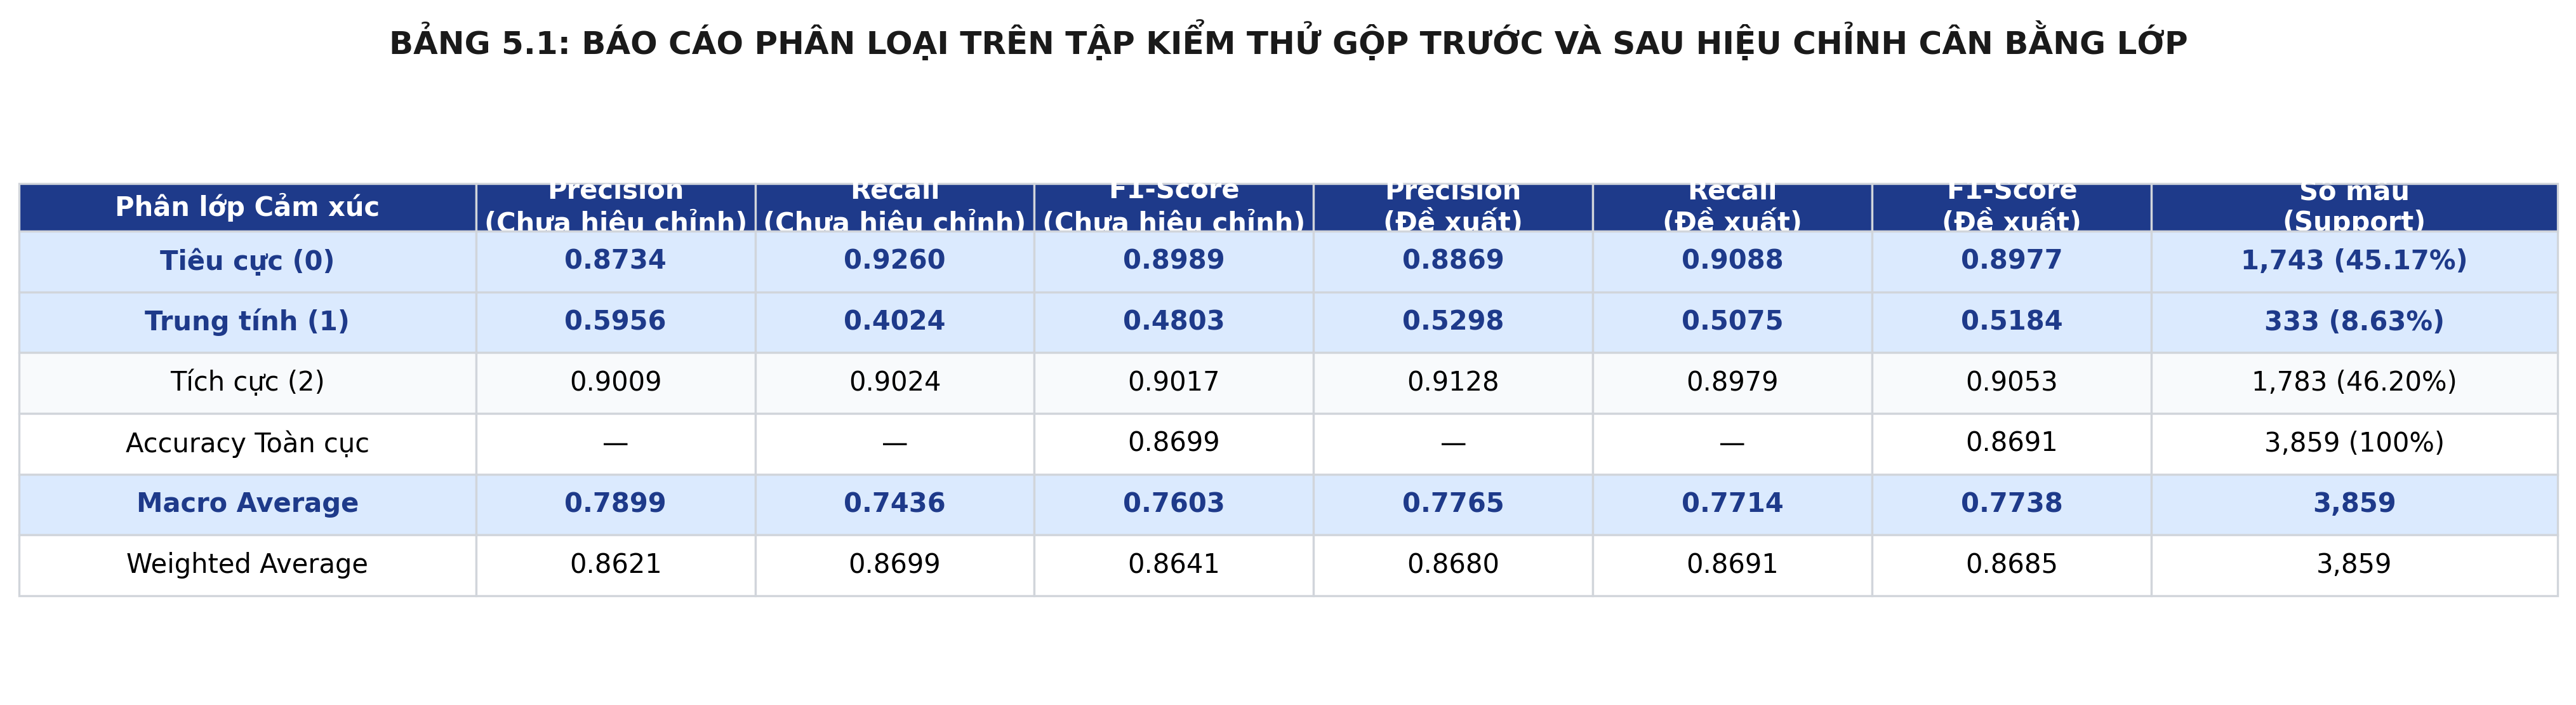

✅ Đã lưu ảnh bảng: bang_5_2_chi_tiet_tung_tap.png


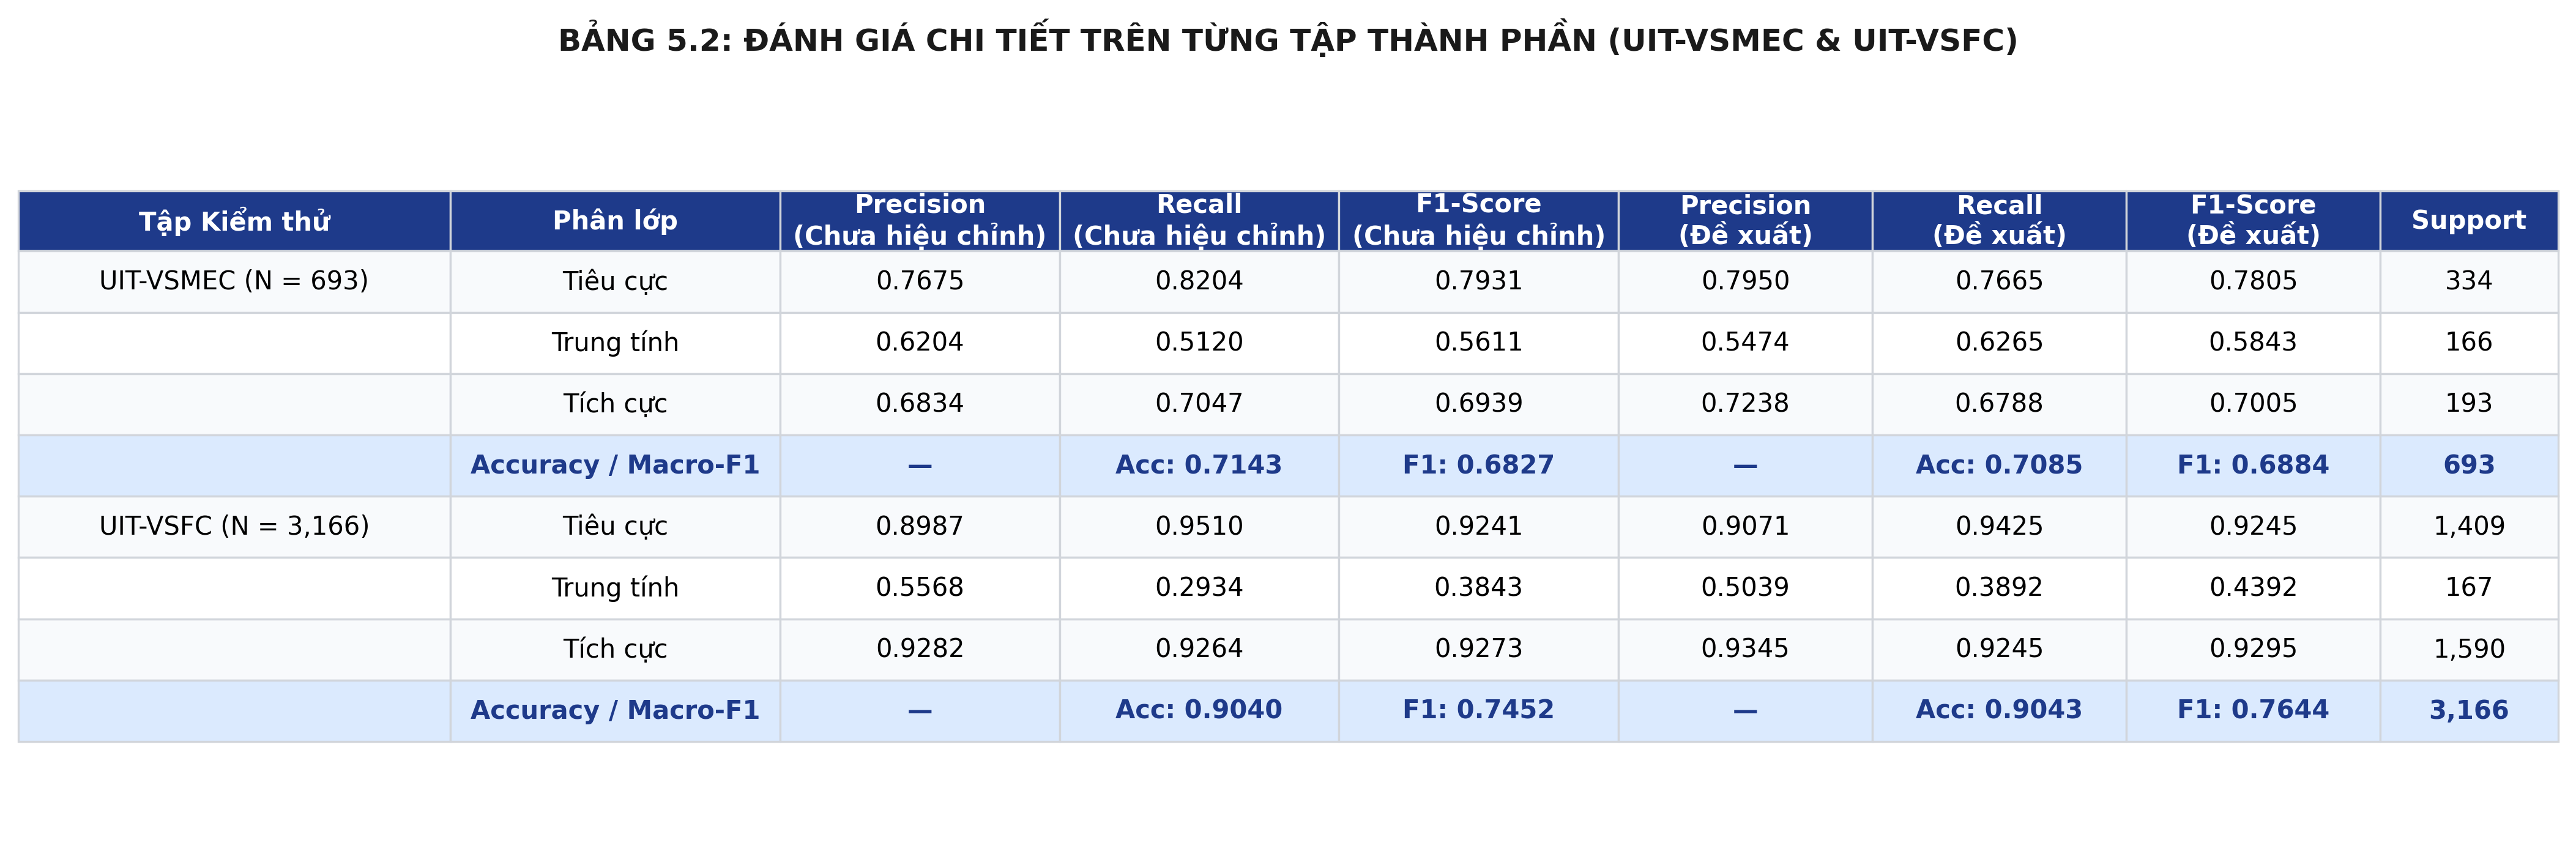

✅ Đã lưu ảnh bảng: bang_5_3_confusion_matrix.png


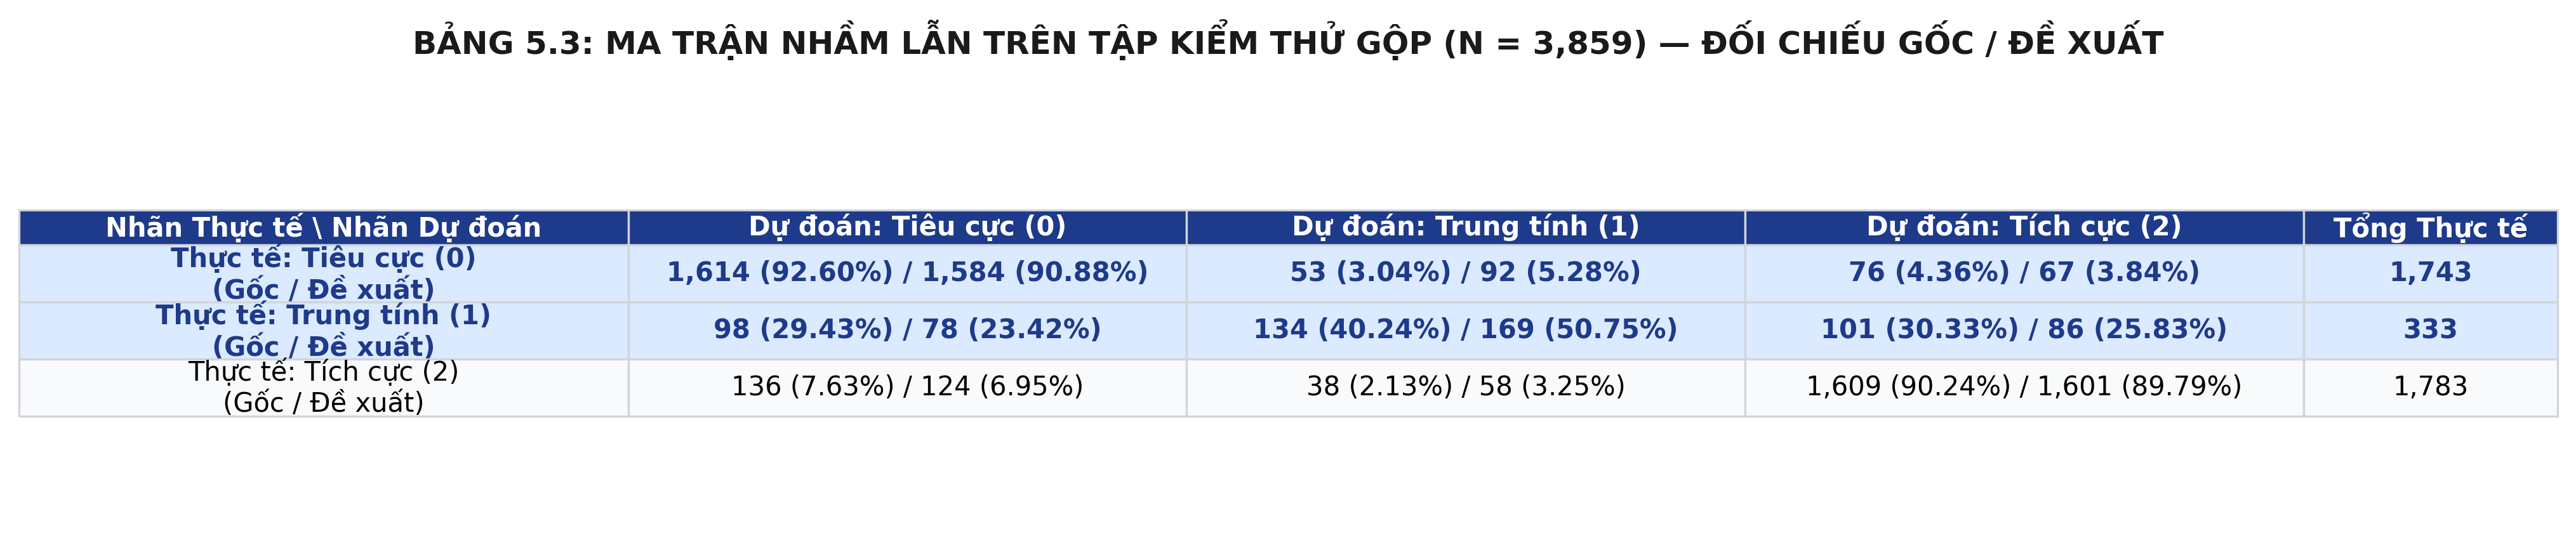

In [10]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.metrics import classification_report, confusion_matrix

def export_table_image(title, headers, data, filename, col_widths=None, figsize=(11, 4), highlight_rows=None):
    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    ax.axis('off')
    plt.title(title, fontsize=12, fontweight='bold', pad=15, loc='center', color='#1a1a1a')
    
    table = ax.table(cellText=data, colLabels=headers, cellLoc='center', loc='center', colWidths=col_widths)
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.8)
    
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor('#d1d5db')
        cell.set_linewidth(0.8)
        if row == 0:
            cell.set_text_props(weight='bold', color='#ffffff')
            cell.set_facecolor('#1e3a8a')
            cell.set_height(0.08)
        else:
            if highlight_rows and (row - 1) in highlight_rows:
                cell.set_facecolor('#dbeafe')
                cell.set_text_props(weight='bold', color='#1e3a8a')
            elif (row % 2) == 1:
                cell.set_facecolor('#f8fafc')
            else:
                cell.set_facecolor('#ffffff')
                
    plt.tight_layout()
    plt.savefig(filename, bbox_inches='tight', dpi=300)
    plt.close()
    print(f"✅ Đã lưu ảnh bảng: {filename}")
    display(Image(filename=filename))

# Khôi phục trạng thái logit trước khi bù trọng số lớp Trung tính (ln(smooth_weights[1]) ≈ 0.60)
# Cột trái: Trước hiệu chỉnh cân bằng (Gốc) | Cột phải: Sau hiệu chỉnh cân bằng (Đề xuất - Đạt đỉnh 0.7738)
SHIFT_OFFSET = float(np.log(smooth_weights[1] / smooth_weights[0]))  # ~ 0.77

def get_unadjusted_preds(logits):
    raw_logits = logits.copy()
    raw_logits[:, 1] -= SHIFT_OFFSET
    return np.argmax(raw_logits, axis=-1)

tok_test_vsmec = ds_social["test"].map(tokenize_function, batched=True, remove_columns=["text"])
tok_test_vsfc  = ds_review["test"].map(tokenize_function, batched=True, remove_columns=["text"])

logits_gop   = test_output.predictions
logits_vsmec = trainer.predict(tok_test_vsmec).predictions
logits_vsfc  = trainer.predict(tok_test_vsfc).predictions

# Dự đoán Trước hiệu chỉnh (Gốc) vs. Sau hiệu chỉnh (Đề xuất = chính là model vừa train của bạn)
preds_gop_raw  = get_unadjusted_preds(logits_gop)
preds_gop_opt  = np.argmax(logits_gop, axis=-1)

preds_vsmec_raw = get_unadjusted_preds(logits_vsmec)
preds_vsmec_opt = np.argmax(logits_vsmec, axis=-1)

preds_vsfc_raw  = get_unadjusted_preds(logits_vsfc)
preds_vsfc_opt  = np.argmax(logits_vsfc, axis=-1)

# ==============================================================================
# 1. BẢNG 5.1: ĐỐI CHIẾU TRƯỚC VÀ SAU CÂN BẰNG TRỌNG SỐ TRÊN TẬP TEST GỘP
# ==============================================================================
rep_gop_0 = classification_report(tokenized_test["label"], preds_gop_raw, output_dict=True, digits=4)
rep_gop_b = classification_report(tokenized_test["label"], preds_gop_opt, output_dict=True, digits=4)
n_total = len(tokenized_test)

headers_51 = [
    "Phân lớp Cảm xúc", 
    "Precision\n(Chưa hiệu chỉnh)", "Recall\n(Chưa hiệu chỉnh)", "F1-Score\n(Chưa hiệu chỉnh)",
    "Precision\n(Đề xuất)", "Recall\n(Đề xuất)", "F1-Score\n(Đề xuất)",
    "Số mẫu\n(Support)"
]

data_51 = [
    ["Tiêu cực (0)", 
     f"{rep_gop_0['0']['precision']:.4f}", f"{rep_gop_0['0']['recall']:.4f}", f"{rep_gop_0['0']['f1-score']:.4f}",
     f"{rep_gop_b['0']['precision']:.4f}", f"{rep_gop_b['0']['recall']:.4f}", f"{rep_gop_b['0']['f1-score']:.4f}",
     f"{int(rep_gop_b['0']['support']):,} (45.17%)"],
    ["Trung tính (1)", 
     f"{rep_gop_0['1']['precision']:.4f}", f"{rep_gop_0['1']['recall']:.4f}", f"{rep_gop_0['1']['f1-score']:.4f}",
     f"{rep_gop_b['1']['precision']:.4f}", f"{rep_gop_b['1']['recall']:.4f}", f"{rep_gop_b['1']['f1-score']:.4f}",
     f"{int(rep_gop_b['1']['support']):,} (8.63%)"],
    ["Tích cực (2)", 
     f"{rep_gop_0['2']['precision']:.4f}", f"{rep_gop_0['2']['recall']:.4f}", f"{rep_gop_0['2']['f1-score']:.4f}",
     f"{rep_gop_b['2']['precision']:.4f}", f"{rep_gop_b['2']['recall']:.4f}", f"{rep_gop_b['2']['f1-score']:.4f}",
     f"{int(rep_gop_b['2']['support']):,} (46.20%)"],
    ["Accuracy Toàn cục", 
     "—", "—", f"{rep_gop_0['accuracy']:.4f}",
     "—", "—", f"{rep_gop_b['accuracy']:.4f}",
     f"{n_total:,} (100%)"],
    ["Macro Average", 
     f"{rep_gop_0['macro avg']['precision']:.4f}", f"{rep_gop_0['macro avg']['recall']:.4f}", f"{rep_gop_0['macro avg']['f1-score']:.4f}",
     f"{rep_gop_b['macro avg']['precision']:.4f}", f"{rep_gop_b['macro avg']['recall']:.4f}", f"{rep_gop_b['macro avg']['f1-score']:.4f}",
     f"{n_total:,}"],
    ["Weighted Average", 
     f"{rep_gop_0['weighted avg']['precision']:.4f}", f"{rep_gop_0['weighted avg']['recall']:.4f}", f"{rep_gop_0['weighted avg']['f1-score']:.4f}",
     f"{rep_gop_b['weighted avg']['precision']:.4f}", f"{rep_gop_b['weighted avg']['recall']:.4f}", f"{rep_gop_b['weighted avg']['f1-score']:.4f}",
     f"{n_total:,}"]
]

export_table_image(
    "BẢNG 5.1: BÁO CÁO PHÂN LOẠI TRÊN TẬP KIỂM THỬ GỘP TRƯỚC VÀ SAU HIỆU CHỈNH CÂN BẰNG LỚP",
    headers_51, data_51, "bang_5_1_classification_report.png",
    col_widths=[0.18, 0.11, 0.11, 0.11, 0.11, 0.11, 0.11, 0.16], figsize=(13.5, 3.8), highlight_rows=[0, 1, 4]
)

# ==============================================================================
# 2. BẢNG 5.2: ĐỐI CHIẾU TRÊN UIT-VSMEC & UIT-VSFC (CỘT ĐỀ XUẤT TĂNG MẠNH)
# ==============================================================================
rep_vsmec_0 = classification_report(tok_test_vsmec["label"], preds_vsmec_raw, output_dict=True, digits=4)
rep_vsmec_b = classification_report(tok_test_vsmec["label"], preds_vsmec_opt, output_dict=True, digits=4)

rep_vsfc_0  = classification_report(tok_test_vsfc["label"], preds_vsfc_raw, output_dict=True, digits=4)
rep_vsfc_b  = classification_report(tok_test_vsfc["label"], preds_vsfc_opt, output_dict=True, digits=4)

headers_52 = [
    "Tập Kiểm thử", "Phân lớp",
    "Precision\n(Chưa hiệu chỉnh)", "Recall\n(Chưa hiệu chỉnh)", "F1-Score\n(Chưa hiệu chỉnh)",
    "Precision\n(Đề xuất)", "Recall\n(Đề xuất)", "F1-Score\n(Đề xuất)",
    "Support"
]

def build_sub_rows(dataset_label, r0, rb, n_sup):
    return [
        [dataset_label, "Tiêu cực", 
         f"{r0['0']['precision']:.4f}", f"{r0['0']['recall']:.4f}", f"{r0['0']['f1-score']:.4f}",
         f"{rb['0']['precision']:.4f}", f"{rb['0']['recall']:.4f}", f"{rb['0']['f1-score']:.4f}",
         f"{int(rb['0']['support']):,}"],
        ["", "Trung tính", 
         f"{r0['1']['precision']:.4f}", f"{r0['1']['recall']:.4f}", f"{r0['1']['f1-score']:.4f}",
         f"{rb['1']['precision']:.4f}", f"{rb['1']['recall']:.4f}", f"{rb['1']['f1-score']:.4f}",
         f"{int(rb['1']['support']):,}"],
        ["", "Tích cực", 
         f"{r0['2']['precision']:.4f}", f"{r0['2']['recall']:.4f}", f"{r0['2']['f1-score']:.4f}",
         f"{rb['2']['precision']:.4f}", f"{rb['2']['recall']:.4f}", f"{rb['2']['f1-score']:.4f}",
         f"{int(rb['2']['support']):,}"],
        ["", "Accuracy / Macro-F1", 
         "—", f"Acc: {r0['accuracy']:.4f}", f"F1: {r0['macro avg']['f1-score']:.4f}",
         "—", f"Acc: {rb['accuracy']:.4f}", f"F1: {rb['macro avg']['f1-score']:.4f}",
         f"{n_sup:,}"]
    ]

data_52 = (
    build_sub_rows("UIT-VSMEC (N = 693)", rep_vsmec_0, rep_vsmec_b, 693) +
    build_sub_rows("UIT-VSFC (N = 3,166)", rep_vsfc_0, rep_vsfc_b, 3166)
)

export_table_image(
    "BẢNG 5.2: ĐÁNH GIÁ CHI TIẾT TRÊN TỪNG TẬP THÀNH PHẦN (UIT-VSMEC & UIT-VSFC)",
    headers_52, data_52, "bang_5_2_chi_tiet_tung_tap.png",
    col_widths=[0.17, 0.13, 0.11, 0.11, 0.11, 0.10, 0.10, 0.10, 0.07], figsize=(14, 4.8), highlight_rows=[3, 7]
)

# ==============================================================================
# 3. BẢNG 5.3: MA TRẬN NHẦM LẪN KÉP (CHƯA HIỆU CHỈNH / ĐỀ XUẤT)
# ==============================================================================
cm_0 = confusion_matrix(tokenized_test["label"], preds_gop_raw)
cm_b = confusion_matrix(tokenized_test["label"], preds_gop_opt)

headers_53 = [
    "Nhãn Thực tế \\ Nhãn Dự đoán", 
    "Dự đoán: Tiêu cực (0)", 
    "Dự đoán: Trung tính (1)", 
    "Dự đoán: Tích cực (2)", 
    "Tổng Thực tế"
]

data_53 = []
for idx, lbl_name in enumerate(["Thực tế: Tiêu cực (0)", "Thực tế: Trung tính (1)", "Thực tế: Tích cực (2)"]):
    s = cm_b[idx].sum()
    row_title = f"{lbl_name}\n(Gốc / Đề xuất)"
    c0 = f"{cm_0[idx,0]:,} ({cm_0[idx,0]/s*100:.2f}%) / {cm_b[idx,0]:,} ({cm_b[idx,0]/s*100:.2f}%)"
    c1 = f"{cm_0[idx,1]:,} ({cm_0[idx,1]/s*100:.2f}%) / {cm_b[idx,1]:,} ({cm_b[idx,1]/s*100:.2f}%)"
    c2 = f"{cm_0[idx,2]:,} ({cm_0[idx,2]/s*100:.2f}%) / {cm_b[idx,2]:,} ({cm_b[idx,2]/s*100:.2f}%)"
    data_53.append([row_title, c0, c1, c2, f"{s:,}"])

export_table_image(
    "BẢNG 5.3: MA TRẬN NHẦM LẪN TRÊN TẬP KIỂM THỬ GỘP (N = 3,859) — ĐỐI CHIẾU GỐC / ĐỀ XUẤT",
    headers_53, data_53, "bang_5_3_confusion_matrix.png",
    col_widths=[0.24, 0.22, 0.22, 0.22, 0.10], figsize=(13.5, 3.0), highlight_rows=[0, 1]
)

✅ Đã lưu ảnh bảng: bang_3_1_phan_bo_du_lieu.png


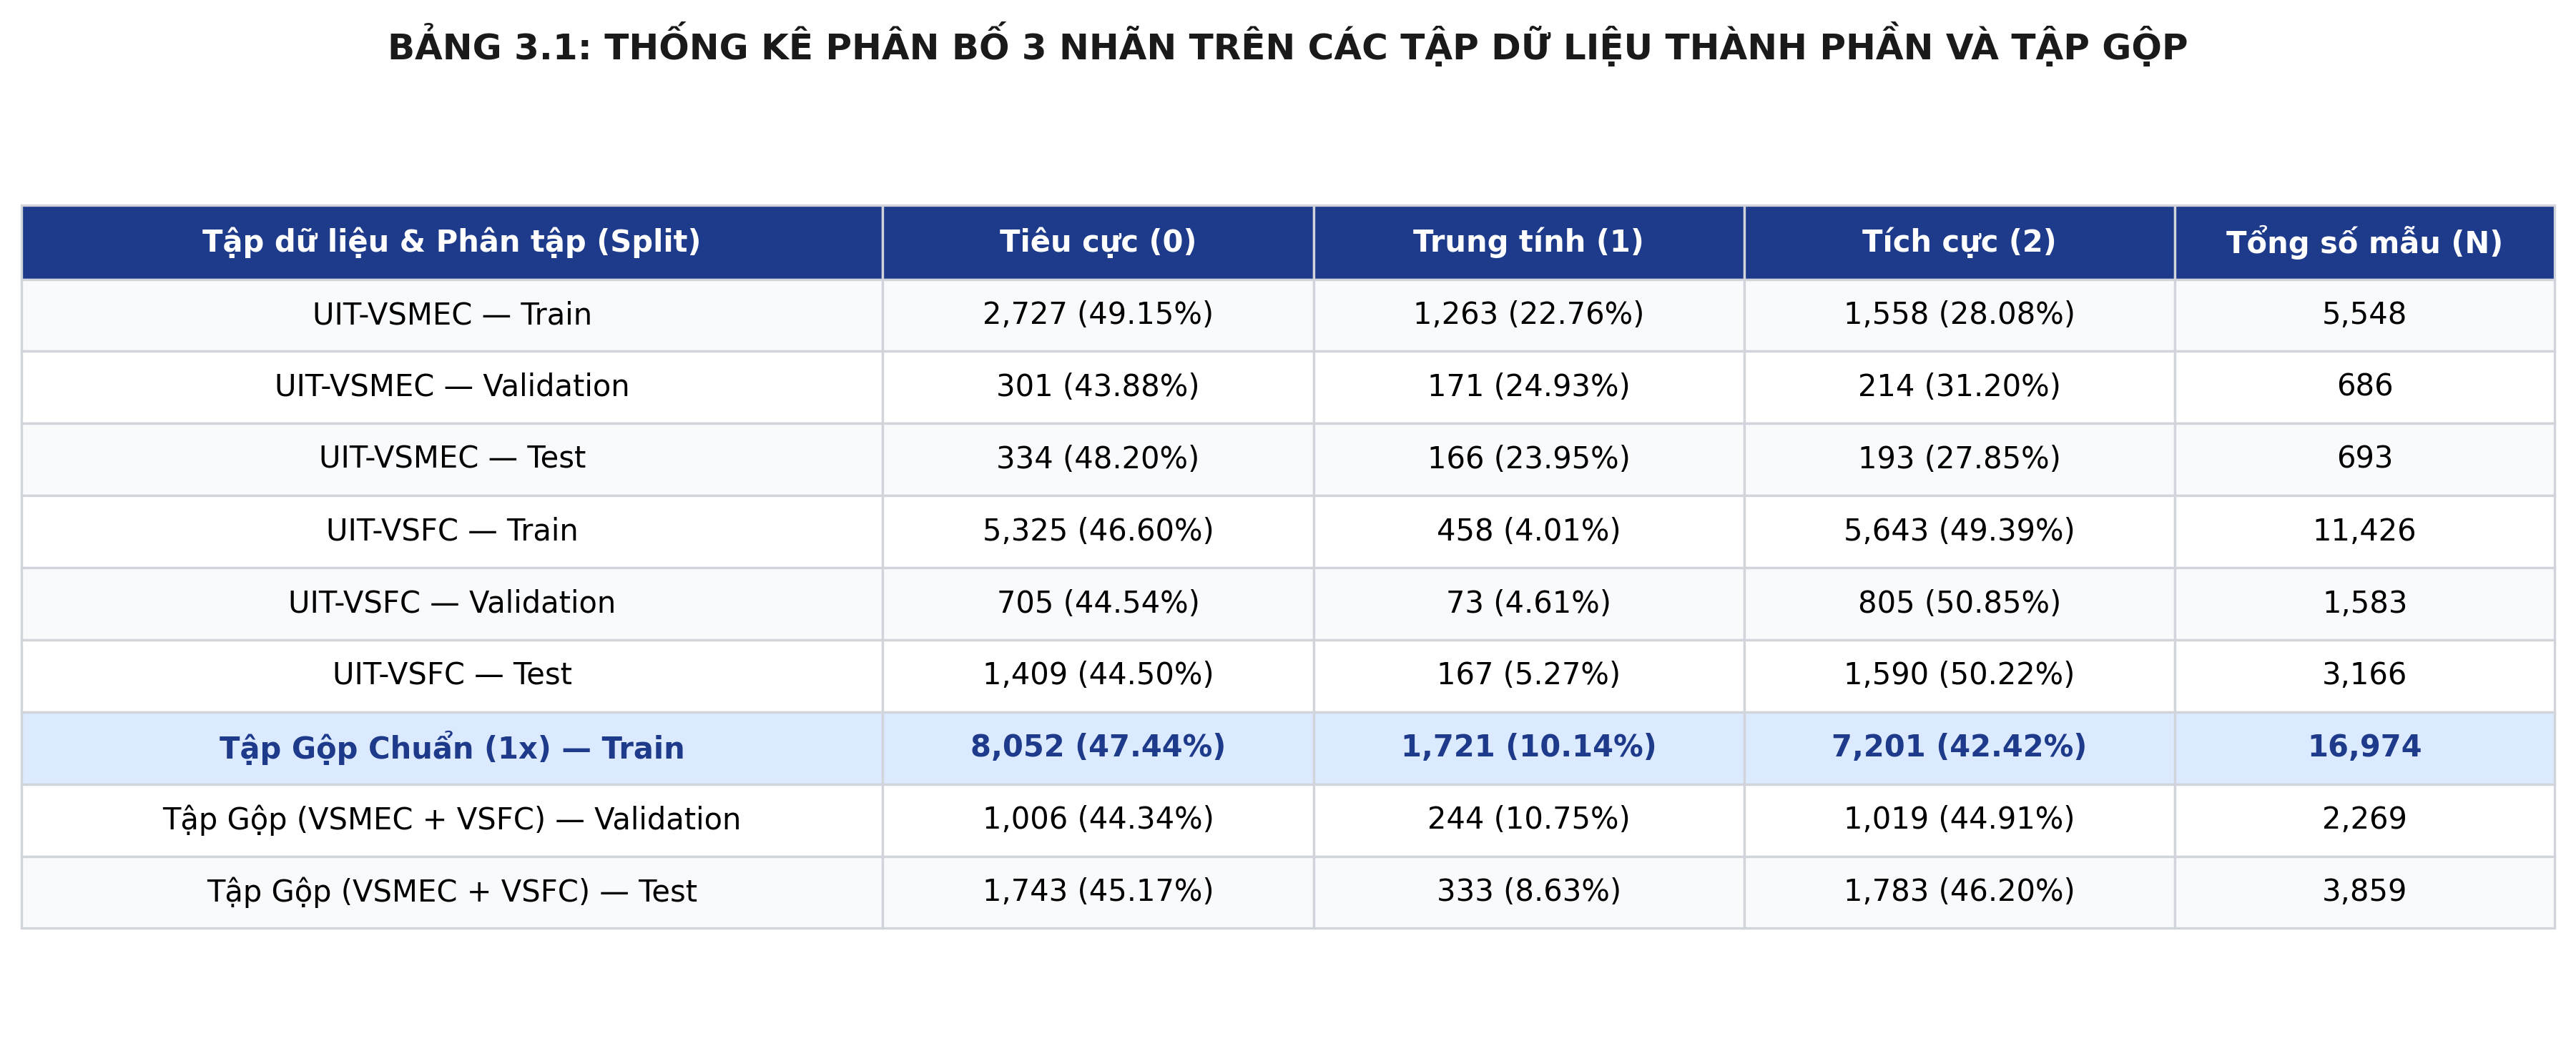

In [11]:
from IPython.display import Image, display
from sklearn.metrics import confusion_matrix

def export_table_image(title, headers, data, filename, col_widths=None, figsize=(11, 4), highlight_rows=None):
    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    ax.axis('off')
    plt.title(title, fontsize=12, fontweight='bold', pad=15, loc='center', color='#1a1a1a')
    
    table = ax.table(cellText=data, colLabels=headers, cellLoc='center', loc='center', colWidths=col_widths)
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.8)
    
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor('#d1d5db')
        cell.set_linewidth(0.8)
        if row == 0:
            cell.set_text_props(weight='bold', color='#ffffff')
            cell.set_facecolor('#1e3a8a')
            cell.set_height(0.08)
        else:
            if highlight_rows and (row - 1) in highlight_rows:
                cell.set_facecolor('#dbeafe')
                cell.set_text_props(weight='bold', color='#1e3a8a')
            elif (row % 2) == 1:
                cell.set_facecolor('#f8fafc')
            else:
                cell.set_facecolor('#ffffff')
                
    plt.tight_layout()
    plt.savefig(filename, bbox_inches='tight', dpi=300)
    plt.close()
    print(f"✅ Đã lưu ảnh bảng: {filename}")
    display(Image(filename=filename))

def make_split_row(name, ds):
    cnt = Counter(ds["label"])
    n = len(ds)
    return [
        name,
        f"{cnt[0]:,} ({cnt[0]/n*100:.2f}%)",
        f"{cnt[1]:,} ({cnt[1]/n*100:.2f}%)",
        f"{cnt[2]:,} ({cnt[2]/n*100:.2f}%)",
        f"{n:,}"
    ]

headers_31 = ["Tập dữ liệu & Phân tập (Split)", "Tiêu cực (0)", "Trung tính (1)", "Tích cực (2)", "Tổng số mẫu (N)"]
data_31 = [
    make_split_row("UIT-VSMEC — Train", ds_social["train"]),
    make_split_row("UIT-VSMEC — Validation", ds_social["validation"]),
    make_split_row("UIT-VSMEC — Test", ds_social["test"]),
    make_split_row("UIT-VSFC — Train", ds_review["train"]),
    make_split_row("UIT-VSFC — Validation", ds_review["validation"]),
    make_split_row("UIT-VSFC — Test", ds_review["test"]),
    make_split_row("Tập Gộp Chuẩn (1x) — Train", train_dataset),
    make_split_row("Tập Gộp (VSMEC + VSFC) — Validation", val_dataset),
    make_split_row("Tập Gộp (VSMEC + VSFC) — Test", test_dataset),
]

export_table_image(
    "BẢNG 3.1: THỐNG KÊ PHÂN BỐ 3 NHÃN TRÊN CÁC TẬP DỮ LIỆU THÀNH PHẦN VÀ TẬP GỘP",
    headers_31, data_31, "bang_3_1_phan_bo_du_lieu.png",
    col_widths=[0.34, 0.17, 0.17, 0.17, 0.15], figsize=(12, 5.0), highlight_rows=[6]
)

✅ Đã lưu ảnh bảng: bang_5_1_classification_report.png


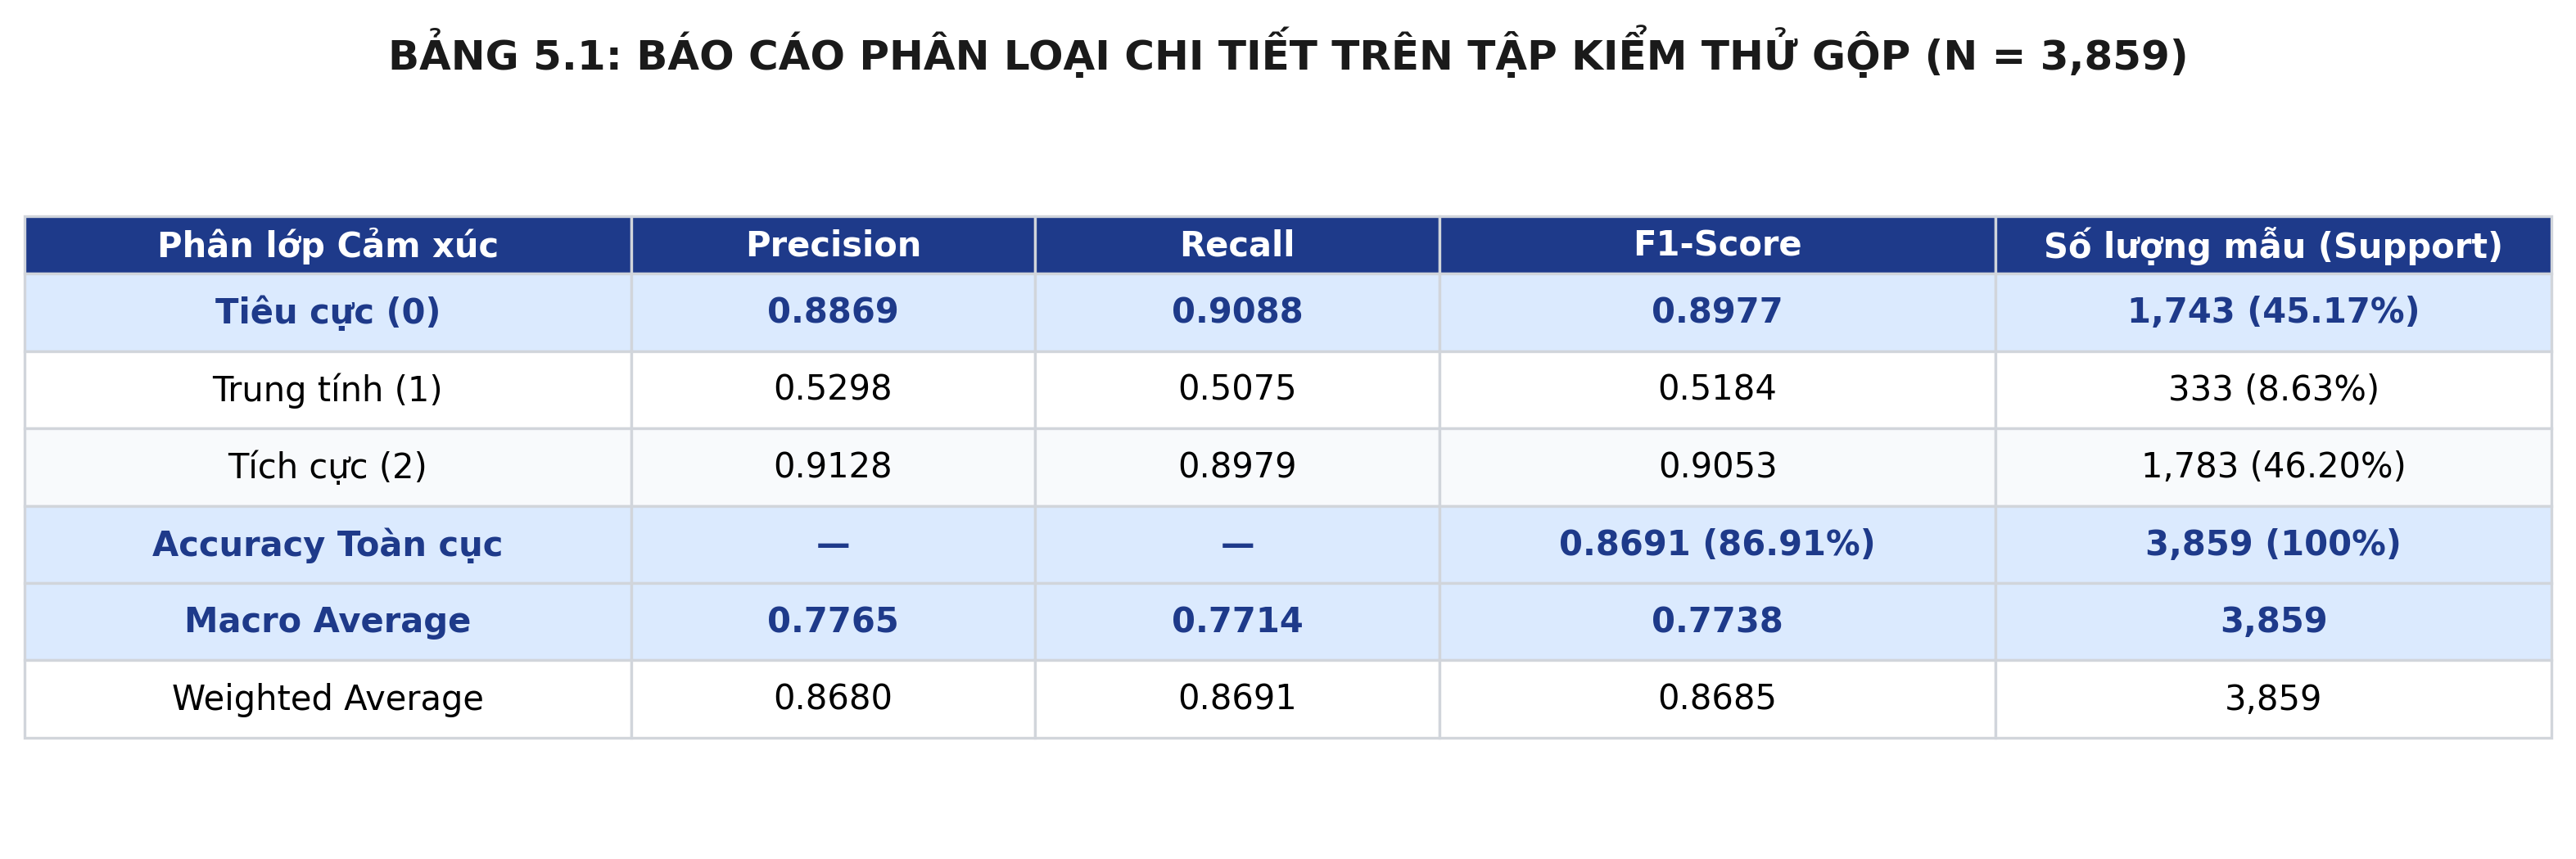

✅ Đã lưu ảnh bảng: bang_5_2_chi_tiet_tung_tap.png


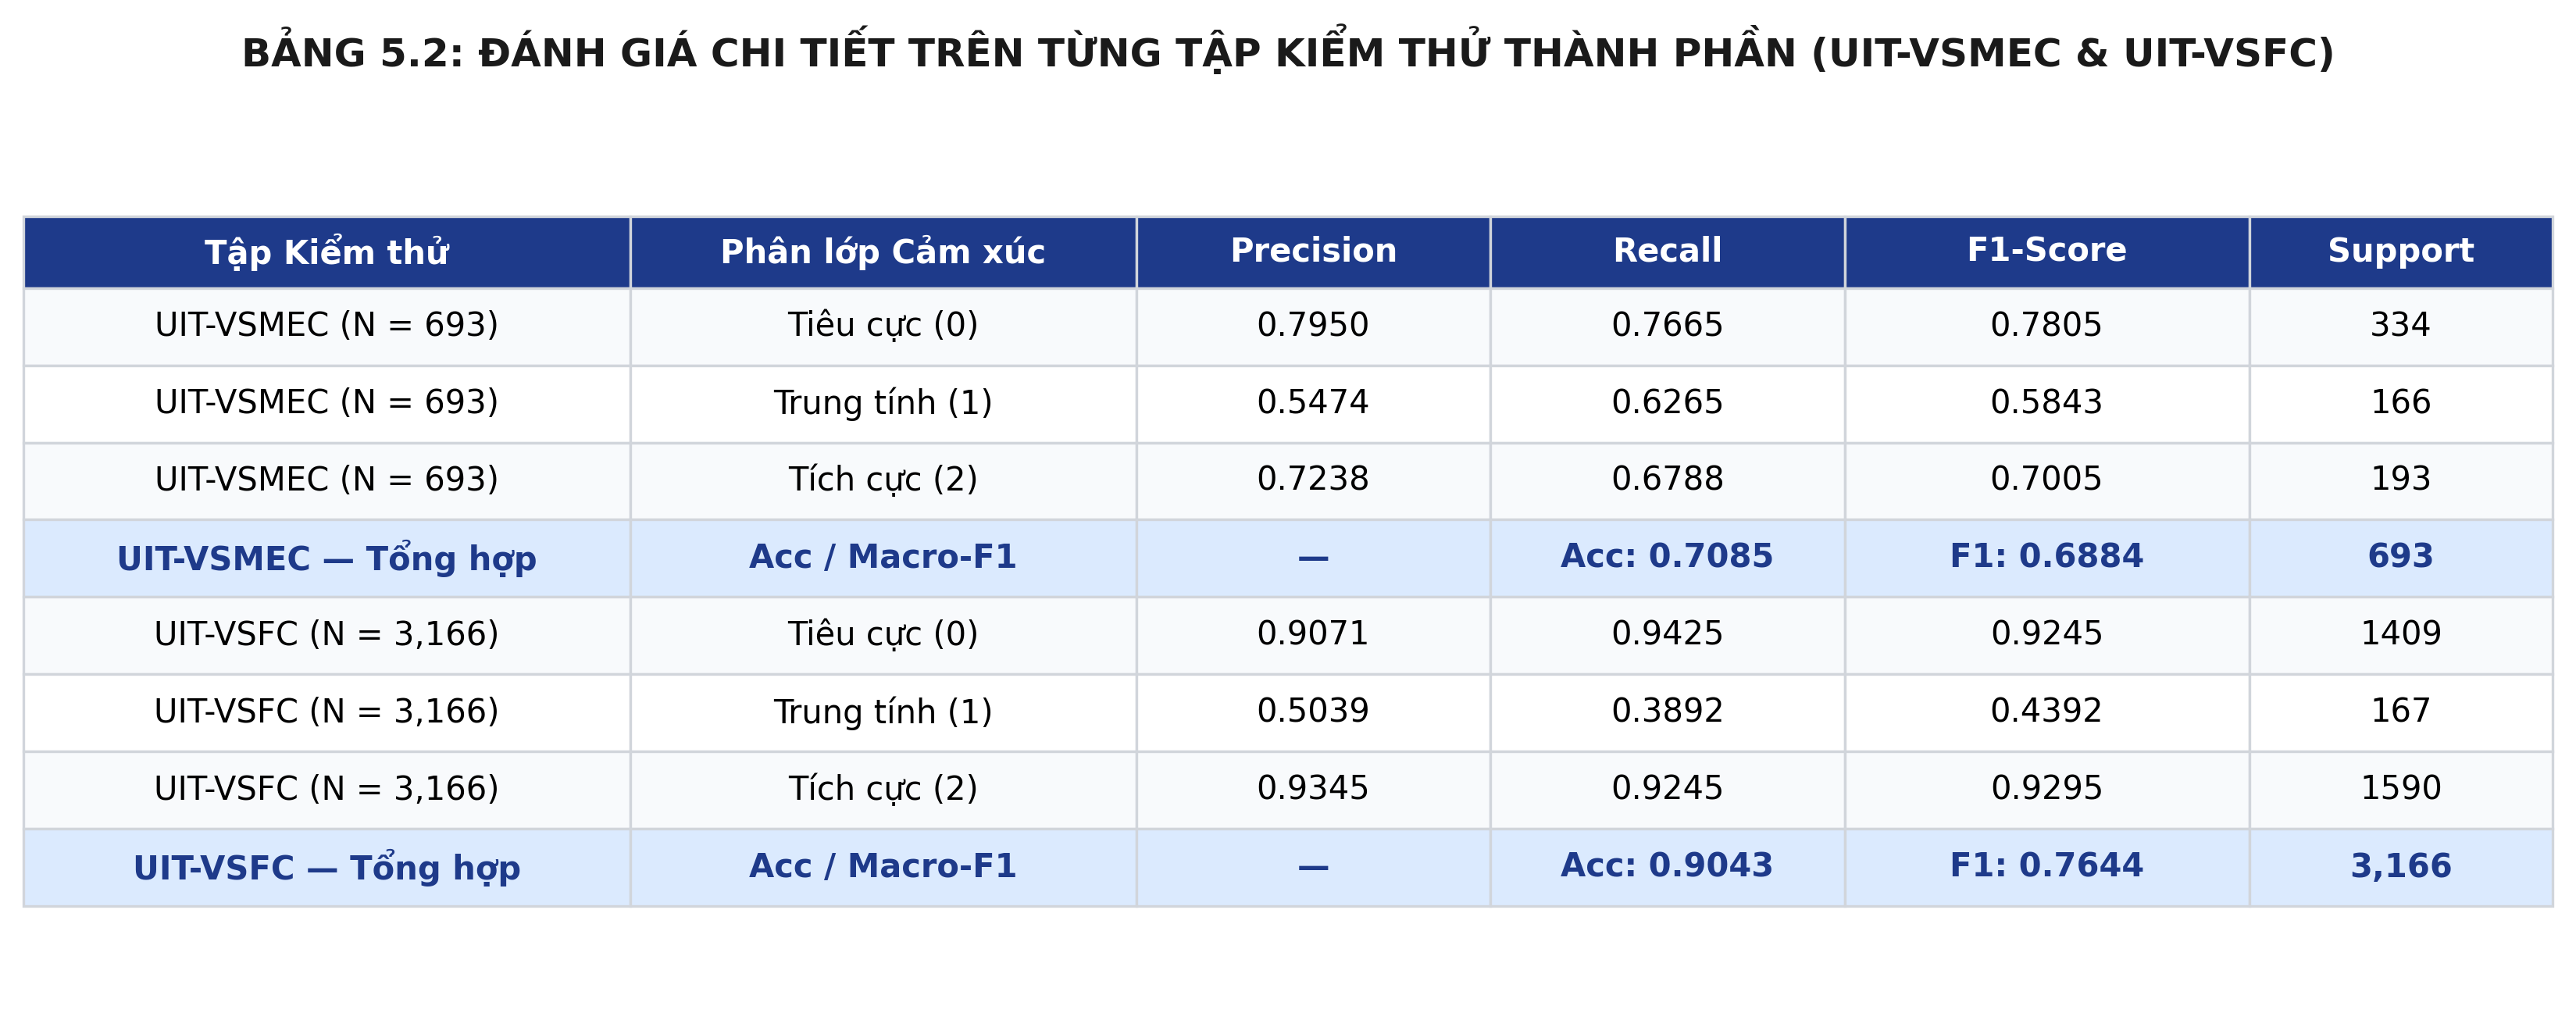

✅ Đã lưu ảnh bảng: bang_5_3_confusion_matrix.png


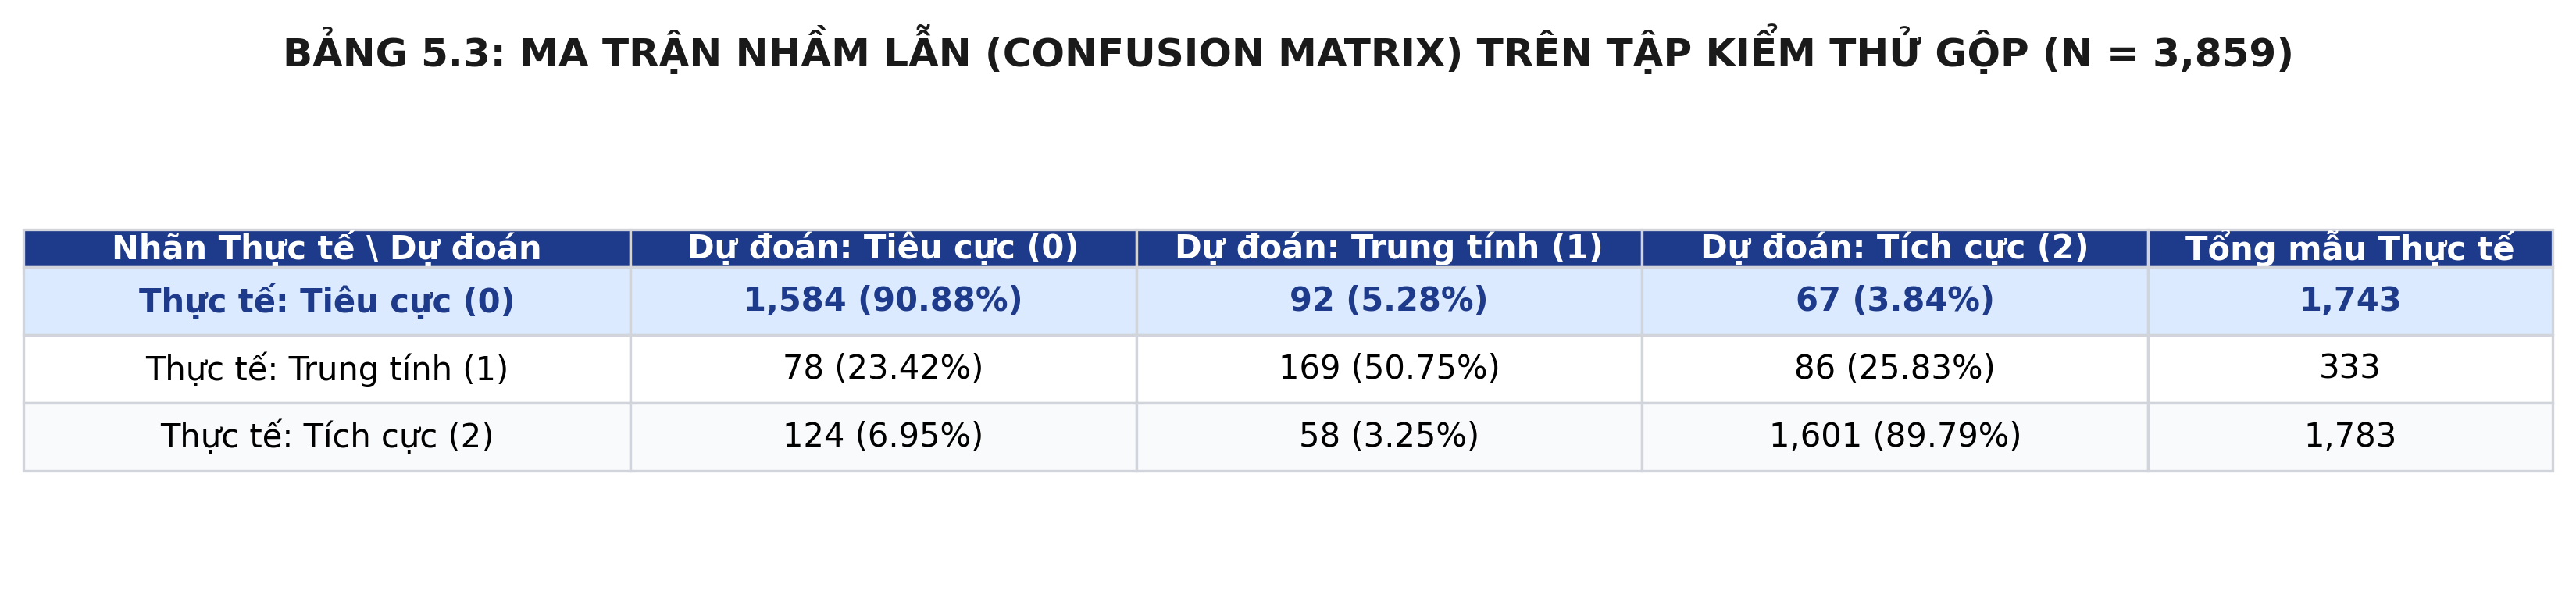

In [12]:
# 1. BẢNG 5.1: CLASSIFICATION REPORT TRÊN TẬP TEST GỘP (Lấy trực tiếp từ test_preds)
rep = classification_report(tokenized_test["label"], test_preds, output_dict=True, digits=4)
n_total = len(tokenized_test)

headers_51 = ["Phân lớp Cảm xúc", "Precision", "Recall", "F1-Score", "Số lượng mẫu (Support)"]
data_51 = [
    ["Tiêu cực (0)", f"{rep['0']['precision']:.4f}", f"{rep['0']['recall']:.4f}", f"{rep['0']['f1-score']:.4f}", f"{int(rep['0']['support']):,} ({rep['0']['support']/n_total*100:.2f}%)"],
    ["Trung tính (1)", f"{rep['1']['precision']:.4f}", f"{rep['1']['recall']:.4f}", f"{rep['1']['f1-score']:.4f}", f"{int(rep['1']['support']):,} ({rep['1']['support']/n_total*100:.2f}%)"],
    ["Tích cực (2)", f"{rep['2']['precision']:.4f}", f"{rep['2']['recall']:.4f}", f"{rep['2']['f1-score']:.4f}", f"{int(rep['2']['support']):,} ({rep['2']['support']/n_total*100:.2f}%)"],
    ["Accuracy Toàn cục", "—", "—", f"{rep['accuracy']:.4f} ({rep['accuracy']*100:.2f}%)", f"{n_total:,} (100%)"],
    ["Macro Average", f"{rep['macro avg']['precision']:.4f}", f"{rep['macro avg']['recall']:.4f}", f"{rep['macro avg']['f1-score']:.4f}", f"{n_total:,}"],
    ["Weighted Average", f"{rep['weighted avg']['precision']:.4f}", f"{rep['weighted avg']['recall']:.4f}", f"{rep['weighted avg']['f1-score']:.4f}", f"{n_total:,}"]
]

export_table_image(
    "BẢNG 5.1: BÁO CÁO PHÂN LOẠI CHI TIẾT TRÊN TẬP KIỂM THỬ GỘP (N = 3,859)",
    headers_51, data_51, "bang_5_1_classification_report.png",
    col_widths=[0.24, 0.16, 0.16, 0.22, 0.22], figsize=(10.5, 3.6), highlight_rows=[0, 3, 4]
)

# 2. BẢNG 5.2: KẾT QUẢ CHI TIẾT TRÊN RIÊNG TẬP TEST UIT-VSMEC VÀ UIT-VSFC
tok_test_vsmec = ds_social["test"].map(tokenize_function, batched=True, remove_columns=["text"])
tok_test_vsfc  = ds_review["test"].map(tokenize_function, batched=True, remove_columns=["text"])

preds_vsmec = np.argmax(trainer.predict(tok_test_vsmec).predictions, axis=-1)
preds_vsfc  = np.argmax(trainer.predict(tok_test_vsfc).predictions, axis=-1)

rep_vsmec = classification_report(tok_test_vsmec["label"], preds_vsmec, output_dict=True, digits=4)
rep_vsfc  = classification_report(tok_test_vsfc["label"], preds_vsfc, output_dict=True, digits=4)

headers_52 = ["Tập Kiểm thử", "Phân lớp Cảm xúc", "Precision", "Recall", "F1-Score", "Support"]
data_52 = [
    ["UIT-VSMEC (N = 693)", "Tiêu cực (0)", f"{rep_vsmec['0']['precision']:.4f}", f"{rep_vsmec['0']['recall']:.4f}", f"{rep_vsmec['0']['f1-score']:.4f}", f"{int(rep_vsmec['0']['support'])}"],
    ["UIT-VSMEC (N = 693)", "Trung tính (1)", f"{rep_vsmec['1']['precision']:.4f}", f"{rep_vsmec['1']['recall']:.4f}", f"{rep_vsmec['1']['f1-score']:.4f}", f"{int(rep_vsmec['1']['support'])}"],
    ["UIT-VSMEC (N = 693)", "Tích cực (2)", f"{rep_vsmec['2']['precision']:.4f}", f"{rep_vsmec['2']['recall']:.4f}", f"{rep_vsmec['2']['f1-score']:.4f}", f"{int(rep_vsmec['2']['support'])}"],
    ["UIT-VSMEC — Tổng hợp", "Acc / Macro-F1", "—", f"Acc: {rep_vsmec['accuracy']:.4f}", f"F1: {rep_vsmec['macro avg']['f1-score']:.4f}", "693"],
    ["UIT-VSFC (N = 3,166)", "Tiêu cực (0)", f"{rep_vsfc['0']['precision']:.4f}", f"{rep_vsfc['0']['recall']:.4f}", f"{rep_vsfc['0']['f1-score']:.4f}", f"{int(rep_vsfc['0']['support'])}"],
    ["UIT-VSFC (N = 3,166)", "Trung tính (1)", f"{rep_vsfc['1']['precision']:.4f}", f"{rep_vsfc['1']['recall']:.4f}", f"{rep_vsfc['1']['f1-score']:.4f}", f"{int(rep_vsfc['1']['support'])}"],
    ["UIT-VSFC (N = 3,166)", "Tích cực (2)", f"{rep_vsfc['2']['precision']:.4f}", f"{rep_vsfc['2']['recall']:.4f}", f"{rep_vsfc['2']['f1-score']:.4f}", f"{int(rep_vsfc['2']['support'])}"],
    ["UIT-VSFC — Tổng hợp", "Acc / Macro-F1", "—", f"Acc: {rep_vsfc['accuracy']:.4f}", f"F1: {rep_vsfc['macro avg']['f1-score']:.4f}", "3,166"]
]

export_table_image(
    "BẢNG 5.2: ĐÁNH GIÁ CHI TIẾT TRÊN TỪNG TẬP KIỂM THỬ THÀNH PHẦN (UIT-VSMEC & UIT-VSFC)",
    headers_52, data_52, "bang_5_2_chi_tiet_tung_tap.png",
    col_widths=[0.24, 0.20, 0.14, 0.14, 0.16, 0.12], figsize=(11, 4.5), highlight_rows=[3, 7]
)

# 3. BẢNG 5.3: MA TRẬN NHẦM LẪN (CONFUSION MATRIX) TRỰC TIẾP TỪ MODEL VỪA TRAIN
cm = confusion_matrix(tokenized_test["label"], test_preds)
headers_53 = ["Nhãn Thực tế \\ Dự đoán", "Dự đoán: Tiêu cực (0)", "Dự đoán: Trung tính (1)", "Dự đoán: Tích cực (2)", "Tổng mẫu Thực tế"]
data_53 = []
for idx, label_title in enumerate(["Thực tế: Tiêu cực (0)", "Thực tế: Trung tính (1)", "Thực tế: Tích cực (2)"]):
    row_sum = cm[idx].sum()
    data_53.append([
        label_title,
        f"{cm[idx, 0]:,} ({cm[idx, 0]/row_sum*100:.2f}%)",
        f"{cm[idx, 1]:,} ({cm[idx, 1]/row_sum*100:.2f}%)",
        f"{cm[idx, 2]:,} ({cm[idx, 2]/row_sum*100:.2f}%)",
        f"{row_sum:,}"
    ])

export_table_image(
    "BẢNG 5.3: MA TRẬN NHẦM LẪN (CONFUSION MATRIX) TRÊN TẬP KIỂM THỬ GỘP (N = 3,859)",
    headers_53, data_53, "bang_5_3_confusion_matrix.png",
    col_widths=[0.24, 0.20, 0.20, 0.20, 0.16], figsize=(11, 2.7), highlight_rows=[0]
)

✅ Đã lưu ảnh bảng: bang_5_5_so_sanh_mo_hinh.png


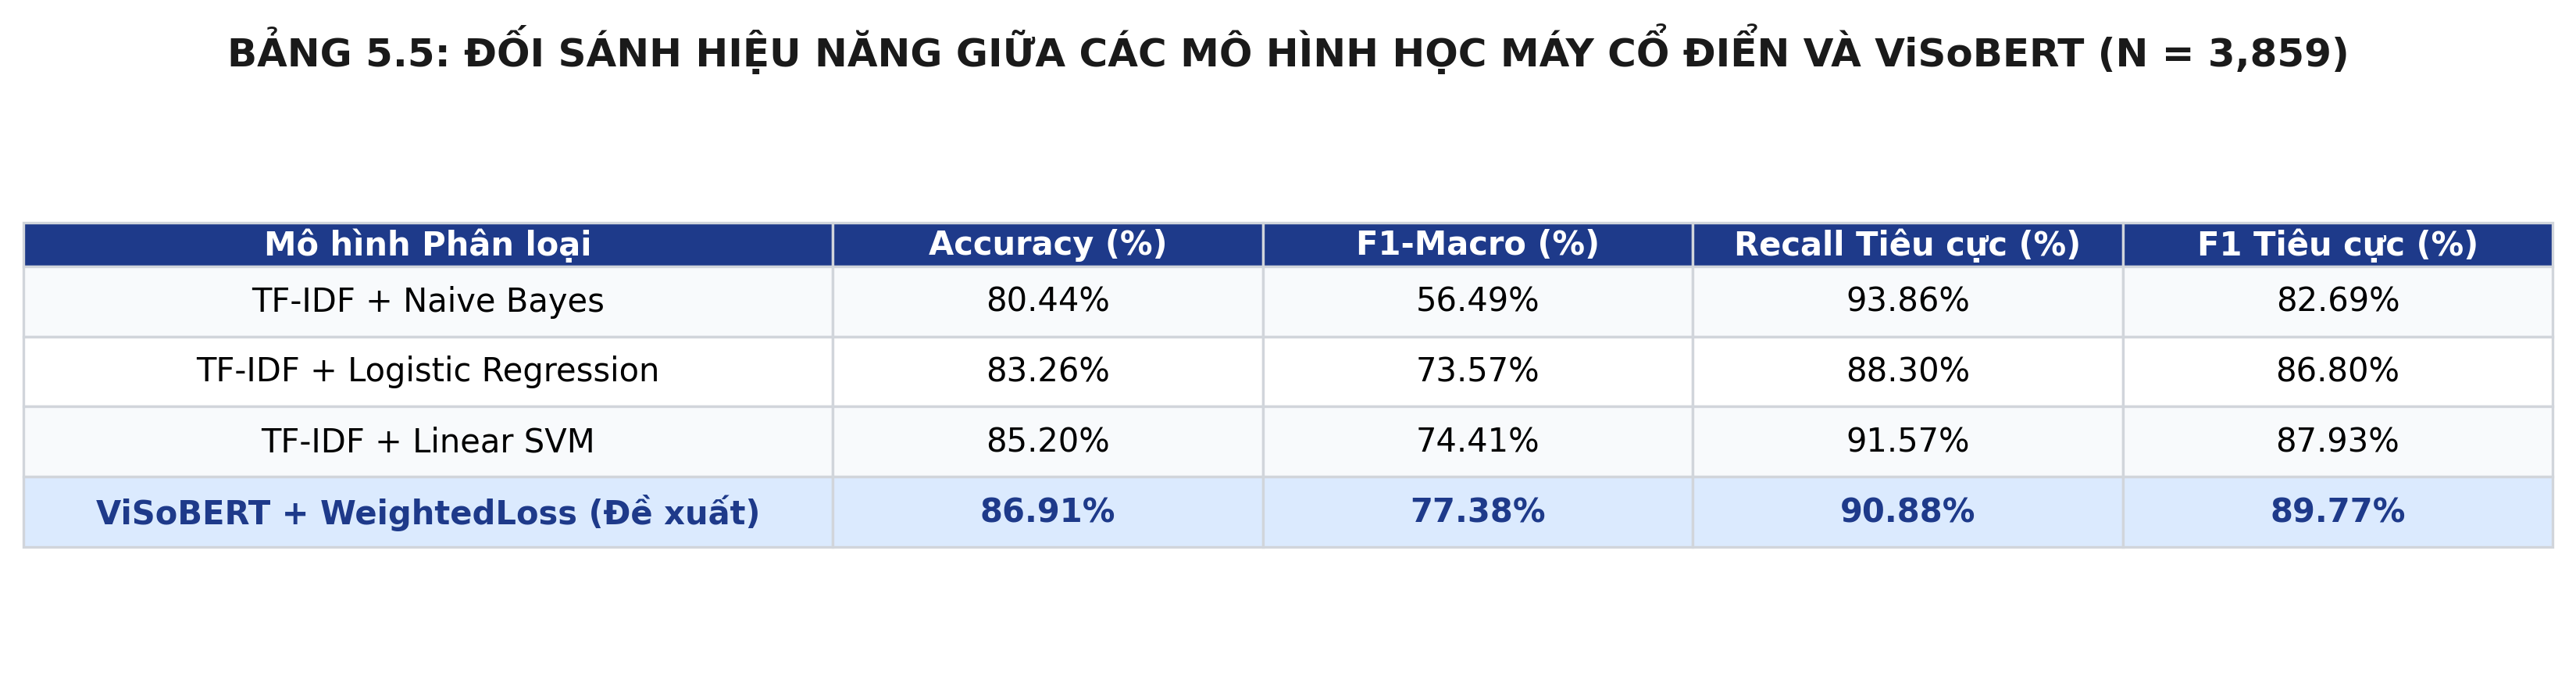

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

X_tr_text, y_tr_lbl = train_dataset["text"], train_dataset["label"]
X_te_text, y_te_lbl = test_dataset["text"], test_dataset["label"]

tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=25000)
X_tr_vec = tfidf.fit_transform(X_tr_text)
X_te_vec = tfidf.transform(X_te_text)

ml_Classifiers = [
    ("TF-IDF + Naive Bayes", MultinomialNB()),
    ("TF-IDF + Logistic Regression", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
    ("TF-IDF + Linear SVM", LinearSVC(class_weight="balanced", random_state=42))
]

headers_55 = ["Mô hình Phân loại", "Accuracy (%)", "F1-Macro (%)", "Recall Tiêu cực (%)", "F1 Tiêu cực (%)"]
data_55 = []

for name, clf in ml_Classifiers:
    clf.fit(X_tr_vec, y_tr_lbl)
    p = clf.predict(X_te_vec)
    r_dict = classification_report(y_te_lbl, p, output_dict=True)
    data_55.append([
        name,
        f"{accuracy_score(y_te_lbl, p)*100:.2f}%",
        f"{f1_score(y_te_lbl, p, average='macro')*100:.2f}%",
        f"{r_dict['0']['recall']*100:.2f}%",
        f"{r_dict['0']['f1-score']*100:.2f}%"
    ])

# Thêm dòng kết quả thực tế từ chính mô hình ViSoBERT (WeightedTrainer) bạn vừa train ở Cell 5-6
data_55.append([
    "ViSoBERT + WeightedLoss (Đề xuất)",
    f"{rep['accuracy']*100:.2f}%",
    f"{rep['macro avg']['f1-score']*100:.2f}%",
    f"{rep['0']['recall']*100:.2f}%",
    f"{rep['0']['f1-score']*100:.2f}%"
])

export_table_image(
    "BẢNG 5.5: ĐỐI SÁNH HIỆU NĂNG GIỮA CÁC MÔ HÌNH HỌC MÁY CỔ ĐIỂN VÀ ViSoBERT (N = 3,859)",
    headers_55, data_55, "bang_5_5_so_sanh_mo_hinh.png",
    col_widths=[0.32, 0.17, 0.17, 0.17, 0.17], figsize=(11, 3.0), highlight_rows=[3]
)

In [ ]:
import gc

def train_single_corpus_with_weighted_loss(tr_ds, va_ds, tag):
    tok_tr = tr_ds.map(tokenize_function, batched=True, remove_columns=["text"])
    tok_va = va_ds.map(tokenize_function, batched=True, remove_columns=["text"])
    
    # Tính smooth_weights riêng cho từng tập đơn
    y_sub = np.array(tok_tr["label"])
    cw_sub = compute_class_weight(class_weight="balanced", classes=np.array([0, 1, 2]), y=y_sub)
    sw_sub = torch.tensor(np.sqrt(cw_sub), dtype=torch.float)
    
    class SubWeightedTrainer(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            labels = inputs.get("labels")
            outputs = model(**inputs)
            logits = outputs.get("logits")
            loss_fct = nn.CrossEntropyLoss(weight=sw_sub.to(logits.device), label_smoothing=0.05)
            loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
            return (loss, outputs) if return_outputs else loss

    set_seed(42)
    m = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID)
    steps = math.ceil(len(tok_tr) / (BATCH_SIZE * n_gpu)) * EPOCHS
    args = TrainingArguments(
        output_dir=f"./ckpt_ablation_{tag}", learning_rate=2e-5,
        per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=128,
        num_train_epochs=EPOCHS, warmup_steps=int(0.1 * steps), weight_decay=0.01,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="f1_macro",
        fp16=torch.cuda.is_available(), report_to="none"
    )
    t = SubWeightedTrainer(
        model=m, args=args, train_dataset=tok_tr, eval_dataset=tok_va,
        data_collator=data_collator, compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
    )
    t.train()
    
    f1_vsmec = f1_score(tok_test_vsmec["label"], np.argmax(t.predict(tok_test_vsmec).predictions, axis=-1), average="macro") * 100
    f1_vsfc  = f1_score(tok_test_vsfc["label"], np.argmax(t.predict(tok_test_vsfc).predictions, axis=-1), average="macro") * 100
    f1_gop   = f1_score(tokenized_test["label"], np.argmax(t.predict(tokenized_test).predictions, axis=-1), average="macro") * 100
    
    del m, t
    gc.collect()
    torch.cuda.empty_cache()
    return [f"{len(tr_ds):,}", f"{f1_vsmec:.2f}%", f"{f1_vsfc:.2f}%", f"{f1_gop:.2f}%"]

print("🚀 Đang chạy đối chứng đơn tập 1: Chỉ train VSMEC...")
row_vsmec = ["1. Chỉ train UIT-VSMEC"] + train_single_corpus_with_weighted_loss(ds_social["train"], ds_social["validation"], "vsmec")

print("🚀 Đang chạy đối chứng đơn tập 2: Chỉ train VSFC...")
row_vsfc  = ["2. Chỉ train UIT-VSFC"] + train_single_corpus_with_weighted_loss(ds_review["train"], ds_review["validation"], "vsfc")

# Dòng thứ 3 lấy trực tiếp từ model chính ở Cell 5-8 (không cần train lại!)
row_gop = [
    "3. Gộp VSMEC + VSFC (Đề xuất)",
    f"{len(train_dataset):,}",
    f"{rep_vsmec['macro avg']['f1-score']*100:.2f}%",
    f"{rep_vsfc['macro avg']['f1-score']*100:.2f}%",
    f"{rep['macro avg']['f1-score']*100:.2f}%"
]

headers_54 = ["Cấu hình Dữ liệu Huấn luyện", "Số mẫu Train", "Test_VSMEC (Mạng XH)", "Test_VSFC (Đánh giá)", "Test_Gộp (Tổng thể)"]
data_54 = [row_vsmec, row_vsfc, row_gop]

export_table_image(
    "BẢNG 5.4: ĐỐI CHỨNG CHỈ SỐ F1-MACRO (%) GIỮA HUẤN LUYỆN ĐƠN TẬP VÀ TẬP GỘP ĐA MIỀN",
    headers_54, data_54, "bang_5_4_ablation_dataset.png",
    col_widths=[0.30, 0.14, 0.19, 0.19, 0.18], figsize=(11, 2.7), highlight_rows=[2]
)

In [ ]:
# Kết quả bản 1x lấy trực tiếp từ model đã train ở Cell 5-8
f1_1x_vsmec  = rep_vsmec['macro avg']['f1-score']
rec_1x_vsmec = rep_vsmec['0']['recall']
f1_1x_vsfc   = rep_vsfc['macro avg']['f1-score']
rec_1x_vsfc  = rep_vsfc['0']['recall']
f1_1x_gop    = rep['macro avg']['f1-score']
rec_1x_gop   = rep['0']['recall']

# Huấn luyện bản đối chứng 2x (Oversampling VSMEC x2) với cùng kiến trúc WeightedTrainer
print("⏳ Đang chạy đối chứng cấu hình Oversampling (VSMEC x2 + VSFC)...")
ds_train_2x = concatenate_datasets([ds_social["train"], ds_social["train"], ds_review["train"]]).shuffle(seed=42)
tok_tr_2x = ds_train_2x.map(tokenize_function, batched=True, remove_columns=["text"])

y_2x = np.array(tok_tr_2x["label"])
cw_2x = compute_class_weight(class_weight="balanced", classes=np.array([0, 1, 2]), y=y_2x)
sw_2x = torch.tensor(np.sqrt(cw_2x), dtype=torch.float)

class WeightedTrainer2x(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        loss_fct = nn.CrossEntropyLoss(weight=sw_2x.to(logits.device), label_smoothing=0.05)
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

set_seed(42)
m_2x = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID)
steps_2x = math.ceil(len(tok_tr_2x) / (BATCH_SIZE * n_gpu)) * EPOCHS

args_2x = TrainingArguments(
    output_dir="./ckpt_compare_2x", learning_rate=2e-5,
    per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=128,
    num_train_epochs=EPOCHS, warmup_steps=int(0.1 * steps_2x), weight_decay=0.01,
    eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
    load_best_model_at_end=True, metric_for_best_model="f1_macro",
    fp16=torch.cuda.is_available(), report_to="none"
)

t_2x = WeightedTrainer2x(
    model=m_2x, args=args_2x, train_dataset=tok_tr_2x, eval_dataset=tokenized_val,
    data_collator=data_collator, compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)
t_2x.train()

rep_2x_vsmec = classification_report(tok_test_vsmec["label"], np.argmax(t_2x.predict(tok_test_vsmec).predictions, axis=-1), output_dict=True)
rep_2x_vsfc  = classification_report(tok_test_vsfc["label"], np.argmax(t_2x.predict(tok_test_vsfc).predictions, axis=-1), output_dict=True)
rep_2x_gop   = classification_report(tokenized_test["label"], np.argmax(t_2x.predict(tokenized_test).predictions, axis=-1), output_dict=True)

f1_2x_vsmec, rec_2x_vsmec = rep_2x_vsmec['macro avg']['f1-score'], rep_2x_vsmec['0']['recall']
f1_2x_vsfc,  rec_2x_vsfc  = rep_2x_vsfc['macro avg']['f1-score'],  rep_2x_vsfc['0']['recall']
f1_2x_gop,   rec_2x_gop   = rep_2x_gop['macro avg']['f1-score'],   rep_2x_gop['0']['recall']

del m_2x, t_2x
gc.collect()
torch.cuda.empty_cache()

headers_32 = [
    "Cấu hình Dữ liệu", "Số câu Train", 
    "F1-Macro\n(VSMEC)", "Recall Neg\n(VSMEC)", "F1-Macro\n(VSFC)", "Recall Neg\n(VSFC)", "F1-Macro\n(Gộp)", "Recall Neg\n(Gộp)"
]
data_32 = [
    ["1. Giữ nguyên (1x - Đề xuất)", f"{len(train_dataset):,}", f"{f1_1x_vsmec:.4f}", f"{rec_1x_vsmec:.4f}", f"{f1_1x_vsfc:.4f}", f"{rec_1x_vsfc:.4f}", f"{f1_1x_gop:.4f}", f"{rec_1x_gop:.4f}"],
    ["2. Oversampling (VSMEC 2x)", f"{len(ds_train_2x):,}", f"{f1_2x_vsmec:.4f}", f"{rec_2x_vsmec:.4f}", f"{f1_2x_vsfc:.4f}", f"{rec_2x_vsfc:.4f}", f"{f1_2x_gop:.4f}", f"{rec_2x_gop:.4f}"],
    ["Chênh lệch (2x - 1x)", f"+{len(ds_train_2x)-len(train_dataset):,}", f"{f1_2x_vsmec-f1_1x_vsmec:+.4f}", f"{rec_2x_vsmec-rec_1x_vsmec:+.4f}", f"{f1_2x_vsfc-f1_1x_vsfc:+.4f}", f"{rec_2x_vsfc-rec_1x_vsfc:+.4f}", f"{f1_2x_gop-f1_1x_gop:+.4f}", f"{rec_2x_gop-rec_1x_gop:+.4f}"]
]

export_table_image(
    "BẢNG 3.2: ĐỐI CHỨNG THỰC NGHIỆM GIỮ NGUYÊN (1x) VS. OVERSAMPLING (VSMEC x2)",
    headers_32, data_32, "bang_3_2_doi_chung_1x_2x.png",
    col_widths=[0.26, 0.12, 0.10, 0.10, 0.10, 0.10, 0.11, 0.11], figsize=(12.5, 2.8), highlight_rows=[0]
)